# Typology analysis — which laundering patterns each run catches (analysis A2)

- **What:** per-typology metrics on the **test split** for every finished run, from the saved `predictions.csv` and the 370 annotated attempts in `Data/HI-Small_Patterns.txt`.
- **Why:** the thesis question — which patterns (cycle, fan-in/out, scatter-gather, stack …) a GNN catches on its own and which need engineered features.
- **How:** rebuild the raw transaction order → match every pattern row to one `edge_id` → for each typology keep **all** normal test edges and only that typology's laundering edges → score with the run's saved threshold.
- **Part A** (sections 0–8) is the result: counts, the per-typology table, the heatmap and bar charts. **Part B** (sections 9–13) is an appendix: bootstrap intervals, fresh vs continued attempts, paired contrasts, RWPE / tuned uplift.
- Output: `Outputs/TYPOLOGY/`. Analysis on saved predictions only: no training, no change to any run or to the protocol.

# Part A — what each model catches per typology

## 0. Setup

- Paths, constants, the config numbering of `EXPERIMENTS.md` (mp / readout → 1–7).
- Run registry: every `results.json` under `Outputs/` (28 V0 + 8 RWPE + 8 GFP tuned = 44), labelled as in `Progress_Report.md` (`GIN-5`, `GAT-4 + RWPE`, `PNA-5 + tuned`).

In [1]:
import gc
import glob
import json
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import average_precision_score

DATA = 'Data'
OUT = 'Outputs/TYPOLOGY'
os.makedirs(OUT, exist_ok=True)

SPLITS = ('train', 'val', 'test')
TYPOLOGIES = ['CYCLE', 'FAN-IN', 'FAN-OUT', 'GATHER-SCATTER', 'SCATTER-GATHER', 'STACK', 'BIPARTITE', 'RANDOM']
ROWS = TYPOLOGIES + ['UNANNOTATED', 'ALL LAUNDERING']

# EXPERIMENTS.md appendix: config number from (mp, readout)
CONFIG_NO = {('none', 'base'): 1, ('base', 'base'): 2, ('none', 'full'): 3, ('full', 'full'): 4,
             ('base', 'full'): 5, ('base', 'gfp'): 6, ('none', 'gfp'): 7}
FAMILY = {'gin': 'GIN', 'gat': 'GAT', 'pna': 'PNA', 'transformer': 'TR'}
FAMILY_ORDER = ['GIN', 'GAT', 'PNA', 'TR']
VARIANT_ORDER = ['v0', 'rwpe16', 'tuned']
HEADLINE = (2, 4, 5)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
print(f'pandas {pd.__version__} | numpy {np.__version__}')

pandas 2.2.2 | numpy 1.26.4


In [2]:
def run_label(result):
    '''(family, config, variant, label) of one results.json, e.g. ("GAT", 4, "rwpe16", "GAT-4 + RWPE").'''
    family = FAMILY[result['operator']]
    config = CONFIG_NO[(result['mp'], result['readout'])]
    variant, suffix = 'v0', ''
    if result.get('node_enc', 'none') != 'none':
        variant, suffix = result['node_enc'], ' + RWPE'
    if result.get('gfp_variant', 'v0') != 'v0':
        variant, suffix = result['gfp_variant'], ' + tuned'
    return family, config, variant, f'{family}-{config}{suffix}'


rows = []
for path in sorted(glob.glob('Outputs/**/results.json', recursive=True)):
    result = json.load(open(path))
    family, config, variant, label = run_label(result)
    rows.append({'label': label, 'family': family, 'config': config, 'variant': variant,
                 'headline': config in HEADLINE, 'run': result['run'],
                 'dir': os.path.dirname(path).replace(os.sep, '/'), 'threshold': result['threshold'],
                 'val_f1': result['val_f1']})
runs = pd.DataFrame(rows)
runs['family'] = pd.Categorical(runs['family'], FAMILY_ORDER)
runs['variant'] = pd.Categorical(runs['variant'], VARIANT_ORDER)
runs = runs.sort_values(['variant', 'family', 'config']).reset_index(drop=True)

assert len(runs) == 44, len(runs)
assert runs['label'].is_unique
assert runs['variant'].value_counts().to_dict() == {'v0': 28, 'rwpe16': 8, 'tuned': 8}
assert all(os.path.exists(f'{d}/predictions.csv') for d in runs['dir'])
print(f'{len(runs)} runs, every one with predictions.csv')
display(runs[['label', 'family', 'config', 'variant', 'headline', 'threshold', 'val_f1', 'dir']])

44 runs, every one with predictions.csv


,label,family,config,variant,headline,threshold,val_f1,dir
0,GIN-1,GIN,1,v0,False,0.501961,0.438685,Outputs/GIN/gin_mp-none_readout-base_dir-in
1,GIN-2,GIN,2,v0,True,0.485826,0.553483,Outputs/GIN/gin_mp-base_readout-base_dir-in
2,GIN-3,GIN,3,v0,False,0.561017,0.547794,Outputs/GIN/gin_mp-none_readout-full_dir-in
3,GIN-4,GIN,4,v0,True,0.567947,0.597633,Outputs/GIN/gin_mp-full_readout-full_dir-in
4,GIN-5,GIN,5,v0,True,0.503624,0.608948,Outputs/GIN/gin_mp-base_readout-full_dir-in
5,GIN-6,GIN,6,v0,False,0.645603,0.532810,Outputs/GIN/gin_mp-base_readout-gfp_dir-in
6,GIN-7,GIN,7,v0,False,0.685394,0.319085,Outputs/GIN/gin_mp-none_readout-gfp_dir-in
7,GAT-1,GAT,1,v0,False,0.355363,0.434320,Outputs/GAT/gat_mp-none_readout-base_dir-in
8,GAT-2,GAT,2,v0,True,0.477109,0.497875,Outputs/GAT/gat_mp-base_readout-base_dir-in
9,GAT-3,GAT,3,v0,False,0.479605,0.524327,Outputs/GAT/gat_mp-none_readout-full_dir-in


## 1. Rebuild the raw transaction order

- `edge_id` = row of `Data/edge_features.csv` = row of the raw file after the exact `Data_preparation.ipynb` §1 steps: read with the §1 column names, keep `Timestamp < 2022-09-11`, stable sort by `Timestamp`, reset index.
- Rebuilding it gives bank, amount, currency and format per `edge_id` — the columns the patterns file is matched on (`edge_features.csv` does not keep them).
- Checked row by row against `edge_features.csv` (`src_account`, `dst_account`, `label`, `Timestamp`); split boundaries and laundering per split against `Progress_Report.md` §4.
- Banks are read as text (`010` stays `010`) so the leading zeros can be stripped like in the patterns file; this does not change the row order.

In [3]:
RAW_COLS = ['Timestamp', 'src_bank', 'src_account', 'dst_bank', 'dst_account',
            'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency',
            'Payment Format', 'label']

tic = time.time()
raw = pd.read_csv(f'{DATA}/HI-Small_Trans.csv', names=RAW_COLS, header=0,
                  dtype={'src_bank': str, 'dst_bank': str}, low_memory=False)
raw['Timestamp'] = pd.to_datetime(raw['Timestamp'])
n_before, pos_before = len(raw), int(raw['label'].sum())

raw = raw[raw['Timestamp'] < '2022-09-11']
raw = raw.sort_values('Timestamp', kind='stable').reset_index(drop=True)
raw['edge_id'] = np.arange(len(raw))

N_EDGES = len(raw)
T1, T2 = int(N_EDGES * 0.60), int(N_EDGES * 0.80)   # same positional 60/20/20 boundaries
raw['split'] = np.where(raw['edge_id'] < T1, 'train', np.where(raw['edge_id'] < T2, 'val', 'test'))

print(f'raw rows {n_before:,} -> {N_EDGES:,} after truncation | laundering {pos_before:,} -> {int(raw["label"].sum()):,}')
print(f'split boundaries: train < {T1:,} <= val < {T2:,} <= test  ({time.time() - tic:.0f} s)')
assert N_EDGES == 5_077_237 and int(raw['label'].sum()) == 4_522
assert (T1, T2) == (3_046_342, 4_061_789)
laundering_per_split = raw.groupby('split')['label'].sum().to_dict()
print('laundering per split:', laundering_per_split)
assert laundering_per_split == {'train': 2_297, 'val': 1_082, 'test': 1_143}   # Progress_Report.md section 4

raw rows 5,078,345 -> 5,077,237 after truncation | laundering 5,177 -> 4,522
split boundaries: train < 3,046,342 <= val < 4,061,789 <= test  (18 s)


laundering per split: {'test': 1143, 'train': 2297, 'val': 1082}


In [4]:
# the rebuilt order must equal edge_features.csv row by row
tic = time.time()
features = pd.read_csv(f'{DATA}/edge_features.csv',
                       usecols=['src_account', 'dst_account', 'label', 'Timestamp'])
assert len(features) == N_EDGES
assert (features['src_account'].to_numpy() == raw['src_account'].to_numpy()).all()
assert (features['dst_account'].to_numpy() == raw['dst_account'].to_numpy()).all()
assert (features['label'].to_numpy().astype(int) == raw['label'].to_numpy()).all()
assert (pd.to_datetime(features['Timestamp'], format='ISO8601').to_numpy() == raw['Timestamp'].to_numpy()).all()
print(f'rebuilt order == edge_features.csv on src / dst / label / Timestamp for all {N_EDGES:,} edges ({time.time() - tic:.0f} s)')
del features
_ = gc.collect()

rebuilt order == edge_features.csv on src / dst / label / Timestamp for all 5,077,237 edges (35 s)


In [5]:
# keep only the 4,522 laundering edges with their raw columns; strip leading zeros of the bank ids
laundering = raw[raw['label'] == 1].copy()
for col in ('src_bank', 'dst_bank'):
    laundering[col] = laundering[col].str.lstrip('0')
del raw
_ = gc.collect()

assert len(laundering) == 4_522
print(f'laundering edges: {len(laundering):,}')
display(laundering.head(3))

laundering edges: 4,522


,Timestamp,src_bank,src_account,dst_bank,dst_account,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,label,edge_id,split
13229,2022-09-01 00:01:00,70,100428660,15980,80B39E7B0,792.92,US Dollar,792.92,US Dollar,Credit Card,1,13229,train
34081,2022-09-01 00:03:00,70,100428660,11474,805B716C0,29024.33,US Dollar,29024.33,US Dollar,Credit Card,1,34081,train
35555,2022-09-01 00:03:00,70,100428660,113798,80DC756E0,13171425.53,US Dollar,13171425.53,US Dollar,Cheque,1,35555,train


## 2. Parse the patterns file

- `HI-Small_Patterns.txt`: 370 `BEGIN … END` blocks, one typology per block, one raw transaction per line (same 11 columns as the raw file).
- Parser in the style of `GFP_experiments.ipynb` §1, extended to all columns plus `attempt_id` and `typology`.
- Rows after Sep 10 were truncated away with the data (§1 of `Data_preparation.ipynb`) and cannot match any edge.

In [6]:
def parse_patterns(path):
    '''One row per transaction of the patterns file with its typology and attempt id (1-based, file order).'''
    rows, attempt_id, typology = [], 0, None
    for line in open(path, encoding='utf-8'):
        line = line.strip()
        if line.startswith('BEGIN LAUNDERING ATTEMPT'):
            attempt_id += 1
            typology = line.split(' - ')[1].split(':')[0].strip()
        elif line.startswith('END LAUNDERING ATTEMPT'):
            typology = None
        elif line:
            assert typology is not None, line
            fields = line.split(',')
            assert len(fields) == 11, line
            rows.append(fields + [typology, attempt_id])
    patterns = pd.DataFrame(rows, columns=RAW_COLS + ['typology', 'attempt_id'])
    patterns['Timestamp'] = pd.to_datetime(patterns['Timestamp'], format='%Y/%m/%d %H:%M')
    for col in ('Amount Received', 'Amount Paid'):
        patterns[col] = patterns[col].astype(float)
    patterns['label'] = patterns['label'].astype(int)
    for col in ('src_bank', 'dst_bank'):
        patterns[col] = patterns[col].str.lstrip('0')
    return patterns


patterns = parse_patterns(f'{DATA}/HI-Small_Patterns.txt')
n_attempts = patterns['attempt_id'].nunique()
assert n_attempts == 370 and (patterns['label'] == 1).all()
assert set(patterns['typology']) == set(TYPOLOGIES)
print(f'{len(patterns):,} pattern rows in {n_attempts} attempts, {patterns["typology"].nunique()} typologies')
print(patterns['typology'].value_counts().to_string())

in_window = patterns['Timestamp'] < '2022-09-11'
rows_per_attempt = patterns.groupby('attempt_id').size()
rows_in_window = patterns[in_window].groupby('attempt_id').size().reindex(rows_per_attempt.index, fill_value=0)
print(f'\nrows after Sep 10 (truncated away): {int((~in_window).sum()):,} of {len(patterns):,}')
print(f'attempts fully after Sep 10: {int((rows_in_window == 0).sum())} | partially truncated: '
      f'{int(((rows_in_window > 0) & (rows_in_window < rows_per_attempt)).sum())} | whole: '
      f'{int((rows_in_window == rows_per_attempt).sum())}')
patterns = patterns[in_window].reset_index(drop=True)
assert len(patterns) == 2_554   # = 3,209 - 655 rows after Sep 10 (the 655 positives lost at truncation)

3,209 pattern rows in 370 attempts, 8 typologies
typology
GATHER-SCATTER    716
SCATTER-GATHER    626
STACK             466
FAN-OUT           342
FAN-IN            318
CYCLE             287
BIPARTITE         263
RANDOM            191

rows after Sep 10 (truncated away): 655 of 3,209
attempts fully after Sep 10: 7 | partially truncated: 102 | whole: 261


## 3. Match pattern rows to edges

- Join on all 11 raw columns (timestamp, banks, accounts, amounts, currencies, format, label).
- Checks: every in-window pattern row finds exactly one `edge_id`, no `edge_id` is used twice, matched + unannotated = 4,522.
- Laundering edges in no annotated attempt = `UNANNOTATED` (`attempt_id` empty).
- Output: `Outputs/TYPOLOGY/edge_typology.csv` — `edge_id, split, typology, attempt_id` for all 4,522 laundering edges (reused by the error and operating-point analyses).

In [7]:
matched = patterns.merge(laundering[RAW_COLS + ['edge_id', 'split']], on=RAW_COLS, how='left')
assert len(matched) == len(patterns), 'a pattern row matched more than one edge'
assert matched['edge_id'].notna().all(), f'{int(matched["edge_id"].isna().sum())} pattern rows without an edge'
assert matched['edge_id'].is_unique, 'an edge matched more than one pattern row'
matched['edge_id'] = matched['edge_id'].astype(int)
print(f'matched {len(matched):,} pattern rows to {matched["edge_id"].nunique():,} distinct edges; '
      f'unmatched 0; duplicates 0')

unannotated = laundering[~laundering['edge_id'].isin(matched['edge_id'])]
edge_typology = pd.concat([
    matched[['edge_id', 'split', 'typology', 'attempt_id']],
    unannotated[['edge_id', 'split']].assign(typology='UNANNOTATED', attempt_id=np.nan),
]).sort_values('edge_id').reset_index(drop=True)
edge_typology['attempt_id'] = edge_typology['attempt_id'].astype('Int64')

assert len(edge_typology) == 4_522 and edge_typology['edge_id'].is_unique
assert (edge_typology['typology'] == 'UNANNOTATED').sum() == 4_522 - 2_554
edge_typology.to_csv(f'{OUT}/edge_typology.csv', index=False)
print(f'annotated {len(matched):,} + unannotated {len(unannotated):,} = {len(edge_typology):,} laundering edges '
      f'-> {OUT}/edge_typology.csv')
print('\nunannotated edges by payment format:', unannotated['Payment Format'].value_counts().to_dict())
display(edge_typology.head(5))

matched 2,554 pattern rows to 2,554 distinct edges; unmatched 0; duplicates 0
annotated 2,554 + unannotated 1,968 = 4,522 laundering edges -> Outputs/TYPOLOGY/edge_typology.csv

unannotated edges by payment format: {'ACH': 1275, 'Cheque': 324, 'Credit Card': 206, 'Cash': 108, 'Bitcoin': 55}


,edge_id,split,typology,attempt_id
0,13229,train,UNANNOTATED,<NA>
1,34081,train,UNANNOTATED,<NA>
2,35555,train,UNANNOTATED,<NA>
3,43234,train,CYCLE,2
4,54384,train,GATHER-SCATTER,3


## 4. Counts per typology and split

- Per typology and split: laundering edges, attempts with at least one edge in the split, and attempts whose edges straddle a split boundary.
- `UNANNOTATED` has no attempts; `ALL LAUNDERING` = every laundering edge of the split.
- Small-sample flag on **test**: fewer than 10 attempts or fewer than 30 edges = "too few to judge". Reviewed 11 Oct: every typology has 17–39 attempts and 45–147 edges on test, so no typology is too few and the test split alone is used.

In [8]:
annotated = edge_typology[edge_typology['typology'] != 'UNANNOTATED']
splits_per_attempt = annotated.groupby('attempt_id')['split'].nunique()

counts = []
for typology in ROWS:
    if typology == 'ALL LAUNDERING':
        subset = edge_typology
    else:
        subset = edge_typology[edge_typology['typology'] == typology]
    row = {'typology': typology}
    for split in SPLITS:
        part = subset[subset['split'] == split]
        row[f'{split}_edges'] = len(part)
        row[f'{split}_attempts'] = int(part['attempt_id'].nunique())
    attempts = subset['attempt_id'].dropna().unique()
    row['attempts_in_window'] = len(attempts)
    row['attempts_crossing_split'] = int((splits_per_attempt.reindex(attempts) > 1).sum())
    row['too_few_test'] = (row['test_attempts'] < 10) or (row['test_edges'] < 30)
    if typology == 'UNANNOTATED':
        row['too_few_test'] = row['test_edges'] < 30   # no attempts to count
    counts.append(row)
counts = pd.DataFrame(counts).set_index('typology')

total = counts.loc['ALL LAUNDERING']
assert (total['train_edges'], total['val_edges'], total['test_edges']) == (2_297, 1_082, 1_143)
assert counts.loc[TYPOLOGIES, ['train_edges', 'val_edges', 'test_edges']].sum().sum() == 2_554
assert total['attempts_in_window'] == 363   # 370 - 7 attempts fully after Sep 10
print('laundering edges and attempts per typology and split (attempts = with >= 1 edge in that split)')
display(counts)
counts.to_csv(f'{OUT}/typology_counts.csv')
print(f'too few to judge on test: {counts.index[counts["too_few_test"]].tolist() or "none"}')

laundering edges and attempts per typology and split (attempts = with >= 1 edge in that split)


,train_edges,train_attempts,val_edges,val_attempts,test_edges,test_attempts,attempts_in_window,attempts_crossing_split,too_few_test
typology,,,,,,,,,
CYCLE,113,33,65,24,65,25,54,25,False
FAN-IN,117,21,64,19,71,19,40,17,False
FAN-OUT,137,25,65,21,74,20,48,17,False
GATHER-SCATTER,215,29,100,26,147,39,51,27,False
SCATTER-GATHER,227,24,147,23,123,23,44,23,False
STACK,169,21,157,28,107,23,40,25,False
BIPARTITE,139,26,50,10,52,17,45,8,False
RANDOM,60,20,45,17,45,17,41,11,False
UNANNOTATED,1120,0,389,0,459,0,0,0,False


too few to judge on test: none


In [9]:
# where each attempt's edges fall: which split sets occur, per typology
split_sets = annotated.groupby('attempt_id').agg(typology=('typology', 'first'),
                                                 splits=('split', lambda s: '+'.join(sorted(set(s), key=SPLITS.index))))
by_set = split_sets.pivot_table(index='typology', columns='splits', values='splits', aggfunc='size', fill_value=0)
by_set = by_set.reindex(TYPOLOGIES)
by_set['total'] = by_set.sum(axis=1)
print('attempts per typology by the set of splits their edges fall in')
display(by_set)

attempts per typology by the set of splits their edges fall in


splits,test,train,train+test,train+val,train+val+test,val,val+test,total
typology,,,,,,,,
CYCLE,10,19,1,10,3,0,11,54
FAN-IN,12,9,0,10,2,2,5,40
FAN-OUT,10,17,0,7,1,4,9,48
GATHER-SCATTER,16,8,1,4,16,0,6,51
SCATTER-GATHER,11,9,1,11,3,1,8,44
STACK,4,8,0,6,7,3,12,40
BIPARTITE,13,22,0,4,0,2,4,45
RANDOM,12,12,0,6,2,6,3,41


## 5. Per-typology metrics — definitions

- Evaluation set for typology T = T's laundering edges on test + **all** 1,014,305 normal test edges. Laundering edges of the other typologies are left out (neither positive nor negative). No undersampling.
- One threshold per run — the saved validation-chosen one, read from the `pred` column. Nothing is re-tuned, nothing is chosen on test.
- Recall = flagged share of T · precision = TP_T / (TP_T + false positives of the split) · F1 from those two · PR-AUC = `average_precision_score` on T vs all normal edges (random baseline = T's share of the set) · recall@1 % / @5 % = share of T inside the top-k highest-scored edges of the **whole** test split (same budget for every run) · attempt recall = share of T's attempts with ≥ 1 flagged test edge.
- **Reading rule:** recall, recall@k and attempt recall are comparable across typologies. Precision, F1 and PR-AUC are comparable only **across runs within one typology**: the normal edges (and so the false positives) are the same for every typology of a run, so a typology with fewer edges always gets a lower precision.

In [10]:
N_TEST = 1_015_448
TOP_FRACS = {'recall_at_1pct': 0.01, 'recall_at_5pct': 0.05}
METRIC_NAMES = ['recall', 'precision', 'f1', 'pr_auc', 'recall_at_1pct', 'recall_at_5pct', 'attempt_recall']

# the 1,143 laundering test edges, sorted by edge_id, and the rows of each typology among them
test_edges = edge_typology[edge_typology['split'] == 'test'].sort_values('edge_id').reset_index(drop=True)
assert len(test_edges) == 1_143
typology_rows = {typology: (test_edges.index.to_numpy() if typology == 'ALL LAUNDERING'
                            else test_edges.index[test_edges['typology'] == typology].to_numpy())
                 for typology in ROWS}
attempt_of_edge = test_edges['attempt_id'].astype(float).to_numpy()   # NaN = unannotated
print({typology: len(rows) for typology, rows in typology_rows.items()})

{'CYCLE': 65, 'FAN-IN': 71, 'FAN-OUT': 74, 'GATHER-SCATTER': 147, 'SCATTER-GATHER': 123, 'STACK': 107, 'BIPARTITE': 52, 'RANDOM': 45, 'UNANNOTATED': 459, 'ALL LAUNDERING': 1143}


In [11]:
def load_test_predictions(run_dir):
    '''Test rows of one predictions.csv -> edge_id, y, prob, pred (numpy, sorted by edge_id).'''
    table = pd.read_csv(f'{run_dir}/predictions.csv', usecols=['split', 'edge_id', 'y', 'prob', 'pred'],
                        dtype={'split': 'category', 'edge_id': np.int64, 'y': np.int8, 'prob': np.float64, 'pred': np.int8})
    table = table[table['split'] == 'test']
    assert len(table) == N_TEST and table['edge_id'].is_monotonic_increasing
    return (table['edge_id'].to_numpy(), table['y'].to_numpy().astype(np.int64),
            table['prob'].to_numpy(), table['pred'].to_numpy().astype(np.int64))


def top_k_mask(prob, frac):
    '''1 for the ceil(frac * n) highest-scored edges (same rule as gnn_core.top_k_metrics), else 0.'''
    k = int(np.ceil(frac * len(prob)))
    mask = np.zeros(len(prob), dtype=np.int64)
    mask[np.argsort(-prob, kind='stable')[:k]] = 1
    return mask


def typology_metrics(prob, pred, top1, top5, attempts, fp, legit_prob):
    '''The seven metrics of one typology: its laundering edges against all normal edges of the split.

    prob / pred / top1 / top5 / attempts: one value per laundering edge of the typology (attempts: NaN when
    unannotated); fp: false positives of the split, shared by every typology; legit_prob: scores of all normal edges.
    '''
    n, tp = len(pred), int(pred.sum())
    recall = tp / n
    precision = tp / (tp + fp) if tp + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if tp else 0.0
    pr_auc = average_precision_score(np.r_[np.zeros(len(legit_prob)), np.ones(n)], np.r_[legit_prob, prob])
    is_annotated = ~np.isnan(attempts)
    attempt_recall = (pd.Series(pred[is_annotated]).groupby(attempts[is_annotated]).max().mean()
                      if is_annotated.any() else np.nan)
    return {'recall': recall, 'precision': precision, 'f1': f1, 'pr_auc': float(pr_auc),
            'recall_at_1pct': float(top1.mean()), 'recall_at_5pct': float(top5.mean()),
            'attempt_recall': float(attempt_recall)}

## 6. Loop over the 44 runs

- One `predictions.csv` at a time (test rows only); the laundering test edges are located by `edge_id`.
- Sanity check per run: the ALL LAUNDERING row must reproduce `test_f1`, `test_precision`, `test_recall`, `test_pr_auc` and `test_recall_at_5pct` of `results.json`.
- The per-edge arrays of each run are kept in memory for the appendix (Part B), so no file is read twice.

In [12]:
metric_rows, run_data = [], {}
tic_all = time.time()
for _, run in runs.iterrows():
    tic = time.time()
    label = run['label']
    edge_id, y, prob, pred = load_test_predictions(run['dir'])
    pos = np.searchsorted(edge_id, test_edges['edge_id'].to_numpy())
    assert (edge_id[pos] == test_edges['edge_id'].to_numpy()).all() and (y[pos] == 1).all() and y.sum() == 1_143

    legit = y == 0
    legit_prob = np.sort(prob[legit])
    n_legit, fp = int(legit.sum()), int(pred[legit].sum())
    top = {name: top_k_mask(prob, frac) for name, frac in TOP_FRACS.items()}
    data = {'prob': prob[pos], 'pred': pred[pos], 'top1': top['recall_at_1pct'][pos], 'top5': top['recall_at_5pct'][pos],
            'fp': fp, 'n_legit': n_legit,
            # normal edges scored >= each laundering edge: the edge's rank among the normal ones (used in Part B)
            'n_legit_ge': n_legit - np.searchsorted(legit_prob, prob[pos], side='left')}
    run_data[label] = data
    result = json.load(open(f'{run["dir"]}/results.json'))

    for typology in ROWS:
        rows_T = typology_rows[typology]
        m = typology_metrics(data['prob'][rows_T], data['pred'][rows_T], data['top1'][rows_T], data['top5'][rows_T],
                             attempt_of_edge[rows_T], fp, legit_prob)
        if typology == 'ALL LAUNDERING':   # must be the run's saved test metrics
            for name in ('recall', 'precision', 'f1'):
                assert abs(m[name] - result[f'test_{name}']) < 1e-9, (label, name, m[name], result[f'test_{name}'])
            assert abs(m['pr_auc'] - result['test_pr_auc']) < 1e-6, (label, m['pr_auc'], result['test_pr_auc'])
            assert abs(m['recall_at_5pct'] - result['test_recall_at_5pct']) < 2e-3, (label, m['recall_at_5pct'])
        metric_rows.append({'run': run['run'], 'label': label, 'family': run['family'], 'config': run['config'],
                            'variant': run['variant'], 'headline': run['headline'], 'typology': typology,
                            'threshold': run['threshold'], 'fp_split': fp, 'n_legit': n_legit,
                            'n_test_edges': len(rows_T), 'n_test_attempts': int(counts.loc[typology, 'test_attempts']),
                            'n_train_edges': int(counts.loc[typology, 'train_edges']),
                            'n_train_attempts': int(counts.loc[typology, 'train_attempts']),
                            'too_few': bool(counts.loc[typology, 'too_few_test']),
                            'pr_auc_random': len(rows_T) / (len(rows_T) + n_legit), **m})

    del edge_id, y, prob, pred, legit, legit_prob, top
    _ = gc.collect()
    all_row = metric_rows[-1]
    print(f'{label:16s} fp {fp:5d} | ALL f1 {all_row["f1"]:.4f} pr_auc {all_row["pr_auc"]:.4f} '
          f'r@5% {all_row["recall_at_5pct"]:.3f} | {time.time() - tic:.0f} s')

metrics = pd.DataFrame(metric_rows)
metrics['variant'] = pd.Categorical(metrics['variant'], VARIANT_ORDER)
metrics['family'] = pd.Categorical(metrics['family'], FAMILY_ORDER)
metrics['typology'] = pd.Categorical(metrics['typology'], ROWS)
metrics = metrics.sort_values(['variant', 'family', 'config', 'typology']).reset_index(drop=True)
assert len(metrics) == 44 * len(ROWS)
metrics.to_csv(f'{OUT}/typology_metrics_test.csv', index=False)
print(f'\n{len(metrics)} run x typology rows in {(time.time() - tic_all) / 60:.1f} min; every run reproduces its '
      f'results.json -> {OUT}/typology_metrics_test.csv')

GIN-1            fp   373 | ALL f1 0.3708 pr_auc 0.3283 r@5% 0.814 | 9 s


GIN-2            fp   206 | ALL f1 0.4556 pr_auc 0.3920 r@5% 0.771 | 12 s


GIN-3            fp   246 | ALL f1 0.4711 pr_auc 0.4348 r@5% 0.861 | 8 s


GIN-4            fp   154 | ALL f1 0.5118 pr_auc 0.4791 r@5% 0.827 | 8 s


GIN-5            fp   233 | ALL f1 0.5252 pr_auc 0.4837 r@5% 0.867 | 7 s


...

GAT-5 + tuned    fp   230 | ALL f1 0.5165 pr_auc 0.4752 r@5% 0.863 | 5 s


PNA-4 + tuned    fp    98 | ALL f1 0.6001 pr_auc 0.5609 r@5% 0.892 | 7 s


PNA-5 + tuned    fp   168 | ALL f1 0.6134 pr_auc 0.5651 r@5% 0.892 | 7 s


TR-4 + tuned     fp   143 | ALL f1 0.6044 pr_auc 0.5636 r@5% 0.865 | 7 s


TR-5 + tuned     fp   141 | ALL f1 0.6074 pr_auc 0.5741 r@5% 0.886 | 7 s

440 run x typology rows in 5.4 min; every run reproduces its results.json -> Outputs/TYPOLOGY/typology_metrics_test.csv


## 7. Results tables

- (a) The one-screen answer: the best V0 run of each operator (highest validation F1 in the family — the protocol's own criterion; GAT-4 ≈ GAT-5, PNA-2 ≈ PNA-4 ≈ PNA-5 and TR-4 ≈ TR-5 are ties within 0.02) × typology, recall and PR-AUC.
- (b) Headline view: V0 configs 2 / 4 / 5 of every operator × typology, four metrics.
- (c) ALL LAUNDERING for all 44 runs = the saved test metrics of `results.json`.
- Full table with counts: `typology_metrics_test.csv` (one row per run × typology).

In [13]:
def pivot(metric, subset, columns='label', order=None):
    '''typology x run table of one metric, rounded.'''
    table = subset.pivot(index='typology', columns=columns, values=metric).reindex(ROWS)
    return (table[order] if order is not None else table).round(3)


best_v0 = (runs[runs['variant'] == 'v0'].sort_values('val_f1', ascending=False)
           .groupby('family', observed=True).head(1).sort_values('family'))
best_labels = best_v0['label'].tolist()
print('(a) best V0 run per operator by validation F1:', dict(zip(best_labels, best_v0['val_f1'].round(3))))
for metric in ('recall', 'pr_auc'):
    print(f'\n{metric} on test — best V0 run per operator x typology')
    display(pivot(metric, metrics[metrics['label'].isin(best_labels)], order=best_labels).T)

(a) best V0 run per operator by validation F1: {'GIN-5': 0.609, 'GAT-4': 0.57, 'PNA-2': 0.651, 'TR-4': 0.644}

recall on test — best V0 run per operator x typology


typology,CYCLE,FAN-IN,FAN-OUT,GATHER-SCATTER,SCATTER-GATHER,STACK,BIPARTITE,RANDOM,UNANNOTATED,ALL LAUNDERING
label,,,,,,,,,,
GIN-5,0.523,0.718,0.730,0.816,0.813,0.617,0.577,0.689,0.009,0.429
GAT-4,0.462,0.789,0.770,0.810,0.699,0.561,0.538,0.511,0.011,0.406
PNA-2,0.738,0.915,0.851,0.939,0.894,0.701,0.750,0.867,0.007,0.507
TR-4,0.723,0.873,0.797,0.912,0.878,0.673,0.712,0.778,0.007,0.487



pr_auc on test — best V0 run per operator x typology


typology,CYCLE,FAN-IN,FAN-OUT,GATHER-SCATTER,SCATTER-GATHER,STACK,BIPARTITE,RANDOM,UNANNOTATED,ALL LAUNDERING
label,,,,,,,,,,
GIN-5,0.201,0.409,0.435,0.700,0.589,0.371,0.224,0.282,0.020,0.484
GAT-4,0.225,0.664,0.495,0.732,0.561,0.386,0.309,0.269,0.013,0.458
PNA-2,0.409,0.631,0.614,0.827,0.679,0.528,0.430,0.548,0.032,0.578
TR-4,0.407,0.695,0.674,0.835,0.770,0.529,0.436,0.549,0.034,0.574


In [14]:
headline = metrics[(metrics['variant'] == 'v0') & metrics['headline']]
labels_headline = [f'{family}-{config}' for family in FAMILY_ORDER for config in HEADLINE]
for metric in ('recall', 'pr_auc', 'recall_at_5pct', 'attempt_recall'):
    print(f'\n(b) {metric} on test — V0 configs 2 / 4 / 5 x typology')
    display(pivot(metric, headline, order=labels_headline))
print('\nrandom PR-AUC baseline per typology (T edges / (T edges + normal edges)):')
print(headline.drop_duplicates('typology').set_index('typology')['pr_auc_random'].map('{:.5f}'.format).to_string())


(b) recall on test — V0 configs 2 / 4 / 5 x typology


label,GIN-2,GIN-4,GIN-5,GAT-2,GAT-4,GAT-5,PNA-2,PNA-4,PNA-5,TR-2,TR-4,TR-5
typology,,,,,,,,,,,,
CYCLE,0.431,0.492,0.523,0.308,0.462,0.477,0.738,0.646,0.723,0.569,0.723,0.646
FAN-IN,0.549,0.718,0.718,0.662,0.789,0.718,0.915,0.803,0.831,0.789,0.873,0.817
FAN-OUT,0.581,0.622,0.730,0.635,0.770,0.689,0.851,0.797,0.851,0.757,0.797,0.770
GATHER-SCATTER,0.701,0.796,0.816,0.769,0.810,0.762,0.939,0.946,0.925,0.884,0.912,0.891
SCATTER-GATHER,0.634,0.772,0.813,0.553,0.699,0.667,0.894,0.862,0.862,0.854,0.878,0.821
STACK,0.495,0.477,0.617,0.477,0.561,0.523,0.701,0.664,0.692,0.654,0.673,0.664
BIPARTITE,0.462,0.519,0.577,0.500,0.538,0.538,0.750,0.731,0.769,0.654,0.712,0.635
RANDOM,0.511,0.556,0.689,0.444,0.511,0.556,0.867,0.822,0.822,0.778,0.778,0.822
UNANNOTATED,0.015,0.004,0.009,0.004,0.011,0.004,0.007,0.004,0.007,0.009,0.007,0.007



(b) pr_auc on test — V0 configs 2 / 4 / 5 x typology


label,GIN-2,GIN-4,GIN-5,GAT-2,GAT-4,GAT-5,PNA-2,PNA-4,PNA-5,TR-2,TR-4,TR-5
typology,,,,,,,,,,,,
CYCLE,0.144,0.235,0.201,0.152,0.225,0.194,0.409,0.409,0.398,0.348,0.407,0.383
FAN-IN,0.227,0.511,0.409,0.548,0.664,0.610,0.631,0.628,0.673,0.562,0.695,0.600
FAN-OUT,0.305,0.460,0.435,0.358,0.495,0.427,0.614,0.637,0.667,0.581,0.674,0.622
GATHER-SCATTER,0.578,0.718,0.700,0.630,0.732,0.677,0.827,0.873,0.830,0.796,0.835,0.796
SCATTER-GATHER,0.388,0.609,0.589,0.376,0.561,0.557,0.679,0.727,0.717,0.715,0.770,0.714
STACK,0.261,0.303,0.371,0.270,0.386,0.320,0.528,0.526,0.501,0.489,0.529,0.482
BIPARTITE,0.145,0.229,0.224,0.194,0.309,0.256,0.430,0.450,0.428,0.375,0.436,0.343
RANDOM,0.180,0.303,0.282,0.123,0.269,0.242,0.548,0.578,0.533,0.454,0.549,0.513
UNANNOTATED,0.023,0.029,0.020,0.011,0.013,0.012,0.032,0.032,0.029,0.033,0.034,0.028



(b) recall_at_5pct on test — V0 configs 2 / 4 / 5 x typology


label,GIN-2,GIN-4,GIN-5,GAT-2,GAT-4,GAT-5,PNA-2,PNA-4,PNA-5,TR-2,TR-4,TR-5
typology,,,,,,,,,,,,
CYCLE,0.785,0.846,0.923,0.923,0.908,0.969,0.954,0.923,0.938,0.938,0.908,0.969
FAN-IN,0.915,0.958,0.972,1.000,0.986,0.986,0.986,1.000,1.000,1.000,0.972,0.986
FAN-OUT,0.757,0.824,0.932,0.973,0.973,0.986,0.959,0.959,0.959,0.946,0.946,0.973
GATHER-SCATTER,0.898,0.952,1.000,1.000,0.993,0.993,0.993,1.000,0.993,1.000,1.000,1.000
SCATTER-GATHER,0.919,0.951,0.992,0.967,0.984,0.984,0.967,0.992,0.984,0.967,0.984,0.976
STACK,0.804,0.850,0.935,0.963,0.925,0.935,0.944,0.935,0.963,0.944,0.925,0.963
BIPARTITE,0.654,0.846,0.904,0.981,0.923,0.923,0.923,0.923,0.942,0.923,0.885,0.885
RANDOM,0.889,0.956,0.978,0.956,0.978,0.978,0.978,0.978,1.000,0.956,0.978,0.978
UNANNOTATED,0.662,0.710,0.725,0.643,0.658,0.671,0.754,0.767,0.769,0.736,0.767,0.721



(b) attempt_recall on test — V0 configs 2 / 4 / 5 x typology


label,GIN-2,GIN-4,GIN-5,GAT-2,GAT-4,GAT-5,PNA-2,PNA-4,PNA-5,TR-2,TR-4,TR-5
typology,,,,,,,,,,,,
CYCLE,0.640,0.760,0.720,0.480,0.640,0.680,0.880,0.800,0.840,0.760,0.880,0.840
FAN-IN,0.737,0.737,0.895,0.684,0.895,0.895,0.895,0.789,0.895,0.842,0.895,0.895
FAN-OUT,0.700,0.650,0.850,0.750,0.800,0.800,0.850,0.750,0.850,0.800,0.800,0.850
GATHER-SCATTER,0.872,0.897,0.923,0.795,0.846,0.846,0.923,0.949,0.949,0.923,0.949,0.923
SCATTER-GATHER,0.913,0.870,1.000,0.739,0.870,0.870,1.000,0.957,1.000,1.000,0.913,1.000
STACK,0.826,0.826,0.913,0.739,0.783,0.826,0.870,0.913,0.913,0.913,0.870,0.913
BIPARTITE,0.882,0.824,0.882,0.588,0.765,0.706,0.941,0.941,0.941,0.941,1.000,1.000
RANDOM,0.824,0.765,0.882,0.706,0.706,0.706,0.941,0.941,0.941,0.941,0.941,0.941
UNANNOTATED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



random PR-AUC baseline per typology (T edges / (T edges + normal edges)):
typology
CYCLE             0.00006
FAN-IN            0.00007
FAN-OUT           0.00007
GATHER-SCATTER    0.00014
SCATTER-GATHER    0.00012
STACK             0.00011
BIPARTITE         0.00005
RANDOM            0.00004
UNANNOTATED       0.00045
ALL LAUNDERING    0.00113


In [15]:
print('(c) ALL LAUNDERING on test, all 44 runs (= results.json; precision / F1 at the saved threshold)')
display(metrics[metrics['typology'] == 'ALL LAUNDERING']
        .set_index('label')[['variant', 'config', 'threshold', 'fp_split', 'recall', 'precision', 'f1', 'pr_auc',
                             'recall_at_1pct', 'recall_at_5pct', 'attempt_recall']].round(4))

(c) ALL LAUNDERING on test, all 44 runs (= results.json; precision / F1 at the saved threshold)


,variant,config,threshold,fp_split,recall,precision,f1,pr_auc,recall_at_1pct,recall_at_5pct,attempt_recall
label,,,,,,,,,,,
GIN-1,v0,1,0.5020,373,0.3018,0.4805,0.3708,0.3283,0.6089,0.8136,0.7268
GIN-2,v0,2,0.4858,206,0.3482,0.6589,0.4556,0.3920,0.6737,0.7708,0.8033
GIN-3,v0,3,0.5610,246,0.3745,0.6350,0.4711,0.4348,0.7017,0.8609,0.7760
GIN-4,v0,4,0.5679,154,0.3902,0.7433,0.5118,0.4791,0.7463,0.8268,0.8033
GIN-5,v0,5,0.5036,233,0.4287,0.6777,0.5252,0.4837,0.7542,0.8670,0.8852
GIN-6,v0,6,0.6456,430,0.3876,0.5074,0.4395,0.3949,0.6570,0.7699,0.8415
GIN-7,v0,7,0.6854,784,0.2476,0.2652,0.2561,0.1975,0.4917,0.7305,0.6448
GAT-1,v0,1,0.3554,344,0.3167,0.5127,0.3916,0.3303,0.6115,0.8408,0.6667
GAT-2,v0,2,0.4771,274,0.3447,0.5898,0.4351,0.3886,0.6728,0.8408,0.6940


## 8. Plots

- `recall_heatmap_test.png`: recall at the saved threshold, 44 runs × 10 typologies, rows grouped by family.
- `bars_<metric>_test.png` for recall, precision, F1 and PR-AUC: one panel per typology, V0 configs 2 / 4 / 5 per operator; every panel uses the same 0-100 % axis; the dashed line in the PR-AUC chart is the random baseline.
- `bars_variants_<metric>_config<5|4>_test.png` for recall and PR-AUC: the same layout for the data variants — per operator V0 vs + RWPE vs + tuned GFP, at config 5 and at config 4.

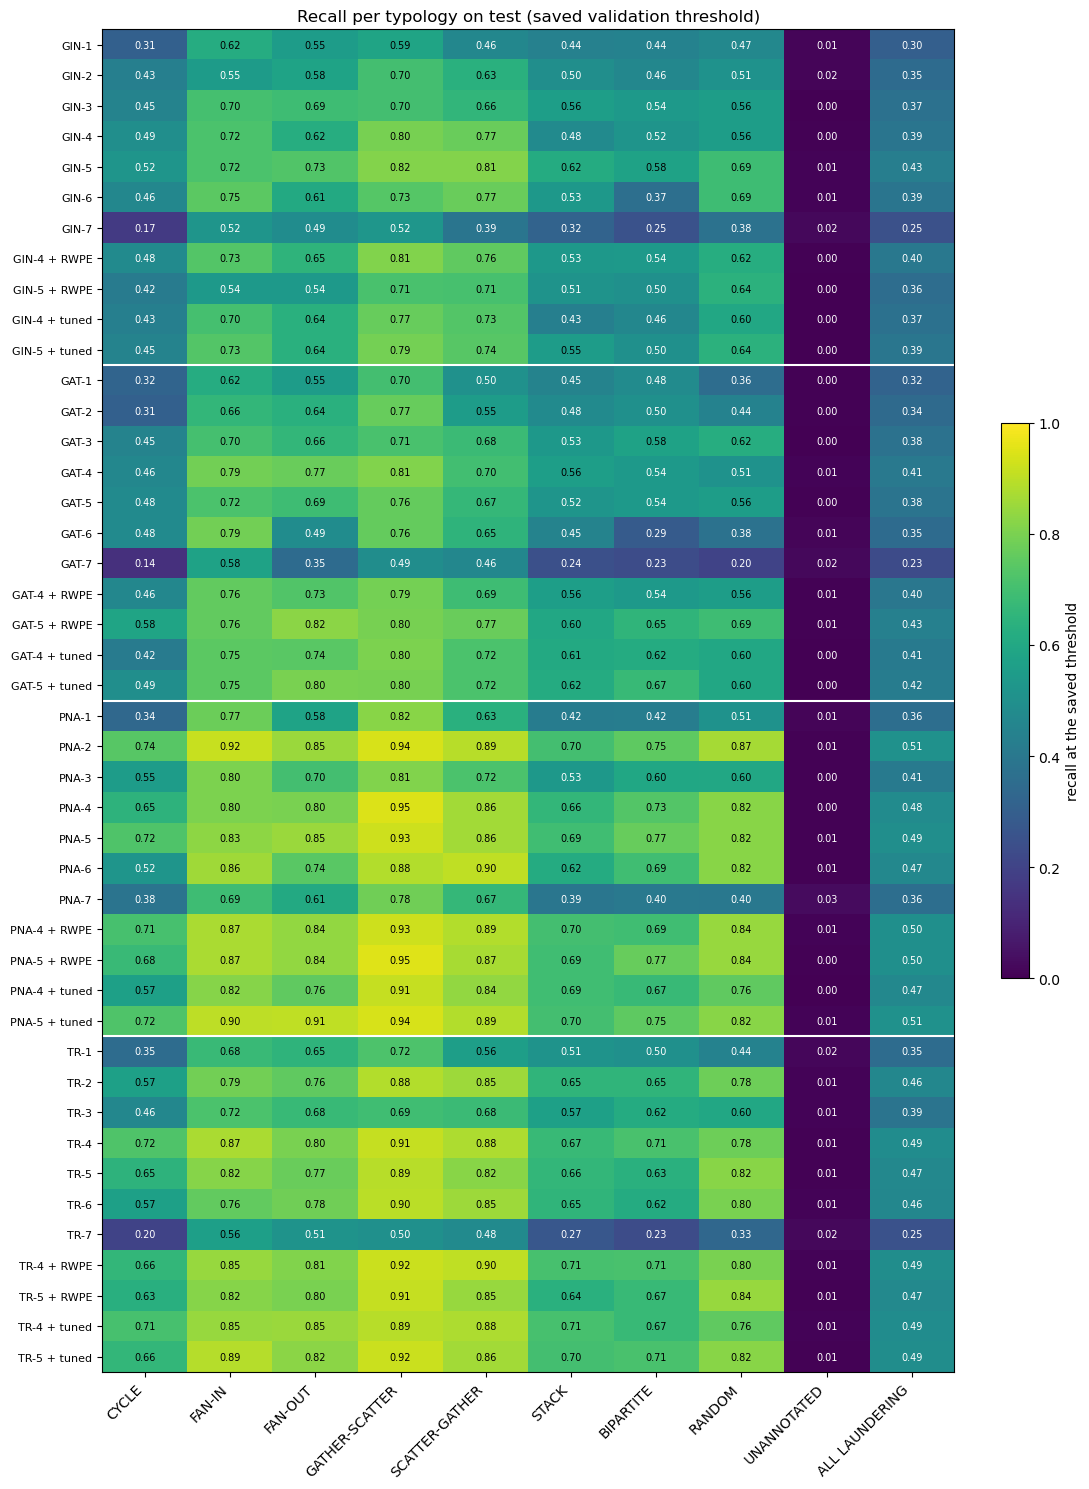

In [16]:
heat_runs = runs.sort_values(['family', 'variant', 'config'])['label'].tolist()
heat = metrics.pivot(index='label', columns='typology', values='recall').reindex(index=heat_runs, columns=ROWS)

fig, ax = plt.subplots(figsize=(11, 15))
image = ax.imshow(heat.to_numpy(), cmap='viridis', vmin=0, vmax=1, aspect='auto')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iat[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=7, color='white' if value < 0.55 else 'black')
ax.set_xticks(range(len(ROWS)))
ax.set_xticklabels(ROWS, rotation=45, ha='right')
ax.set_yticks(range(len(heat_runs)))
ax.set_yticklabels(heat_runs, fontsize=8)
for boundary in np.cumsum(runs.groupby('family', observed=True).size().reindex(FAMILY_ORDER).to_numpy())[:-1]:
    ax.axhline(boundary - 0.5, color='white', lw=1.5)
fig.colorbar(image, ax=ax, fraction=0.03, label='recall at the saved threshold')
ax.set_title('Recall per typology on test (saved validation threshold)')
fig.tight_layout()
fig.savefig(f'{OUT}/recall_heatmap_test.png', dpi=130)
plt.show()

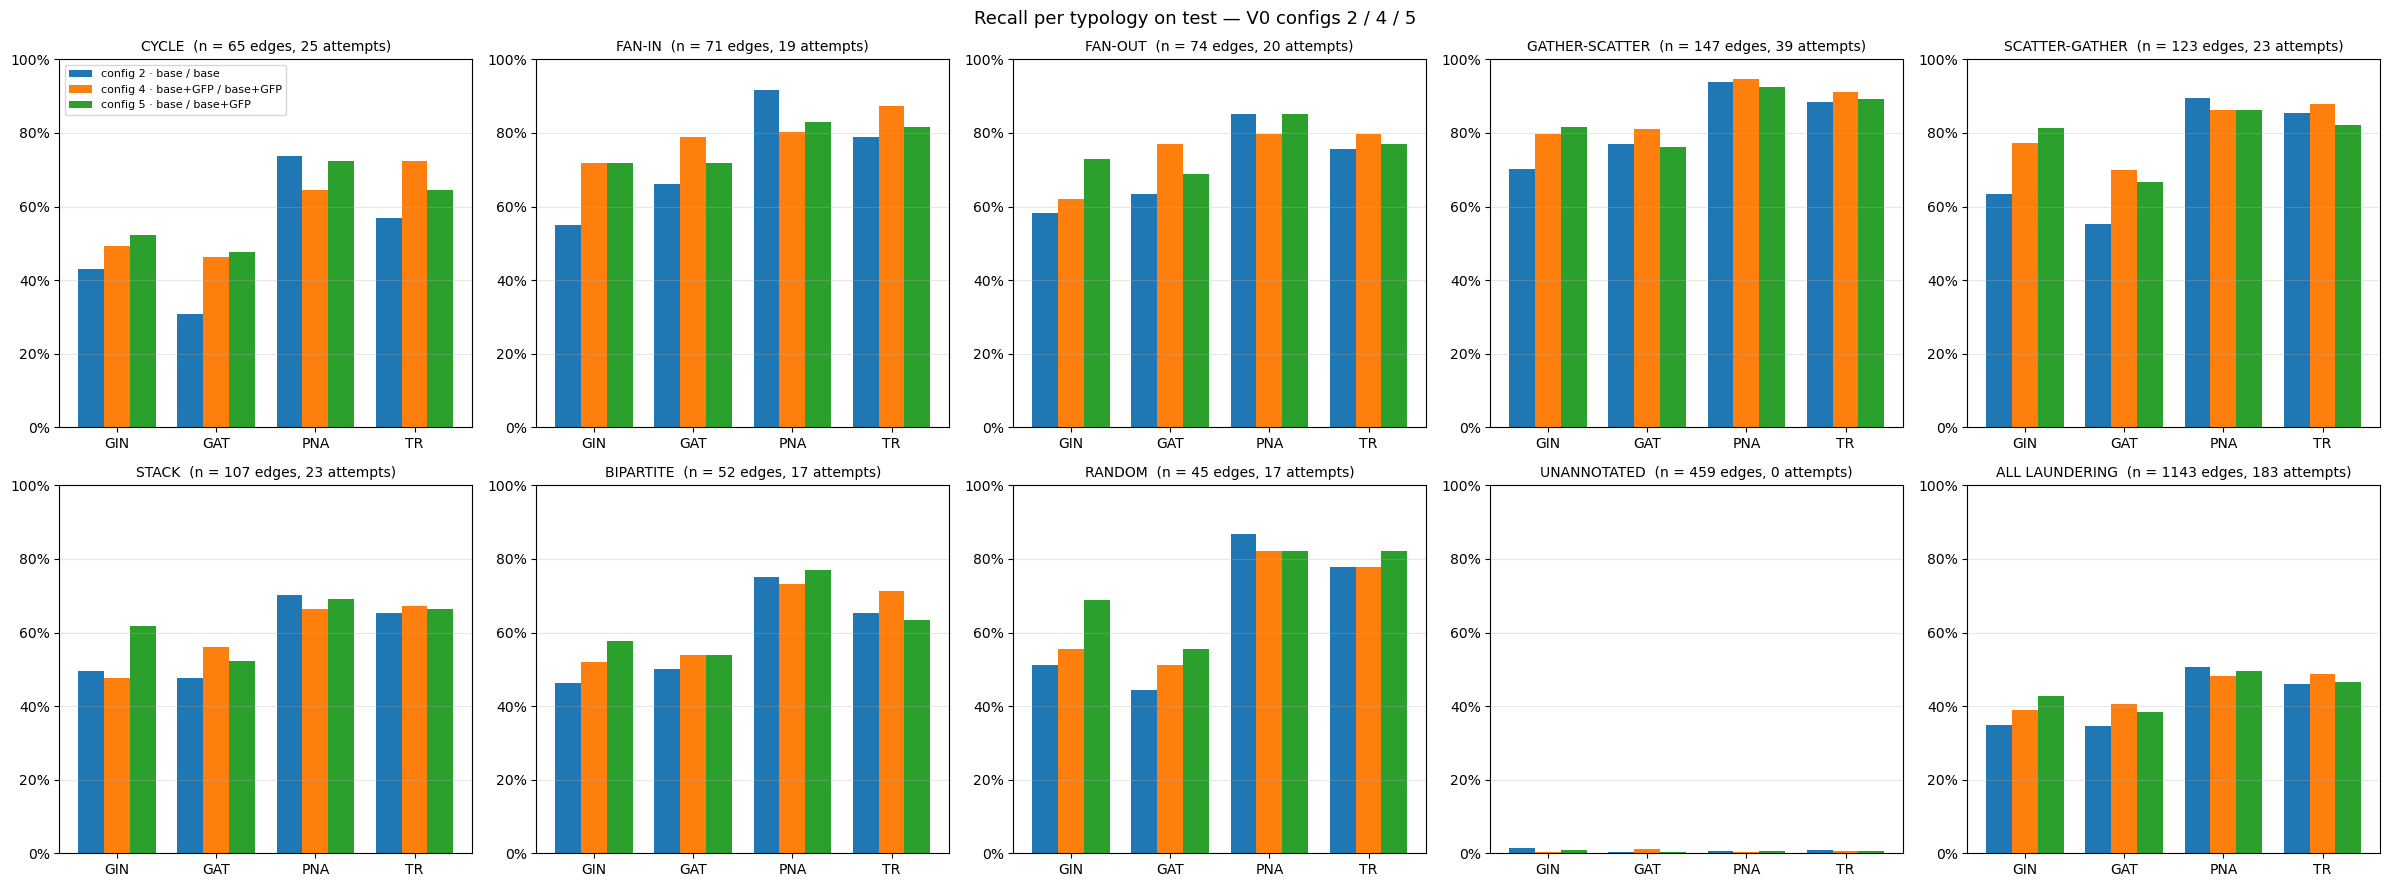

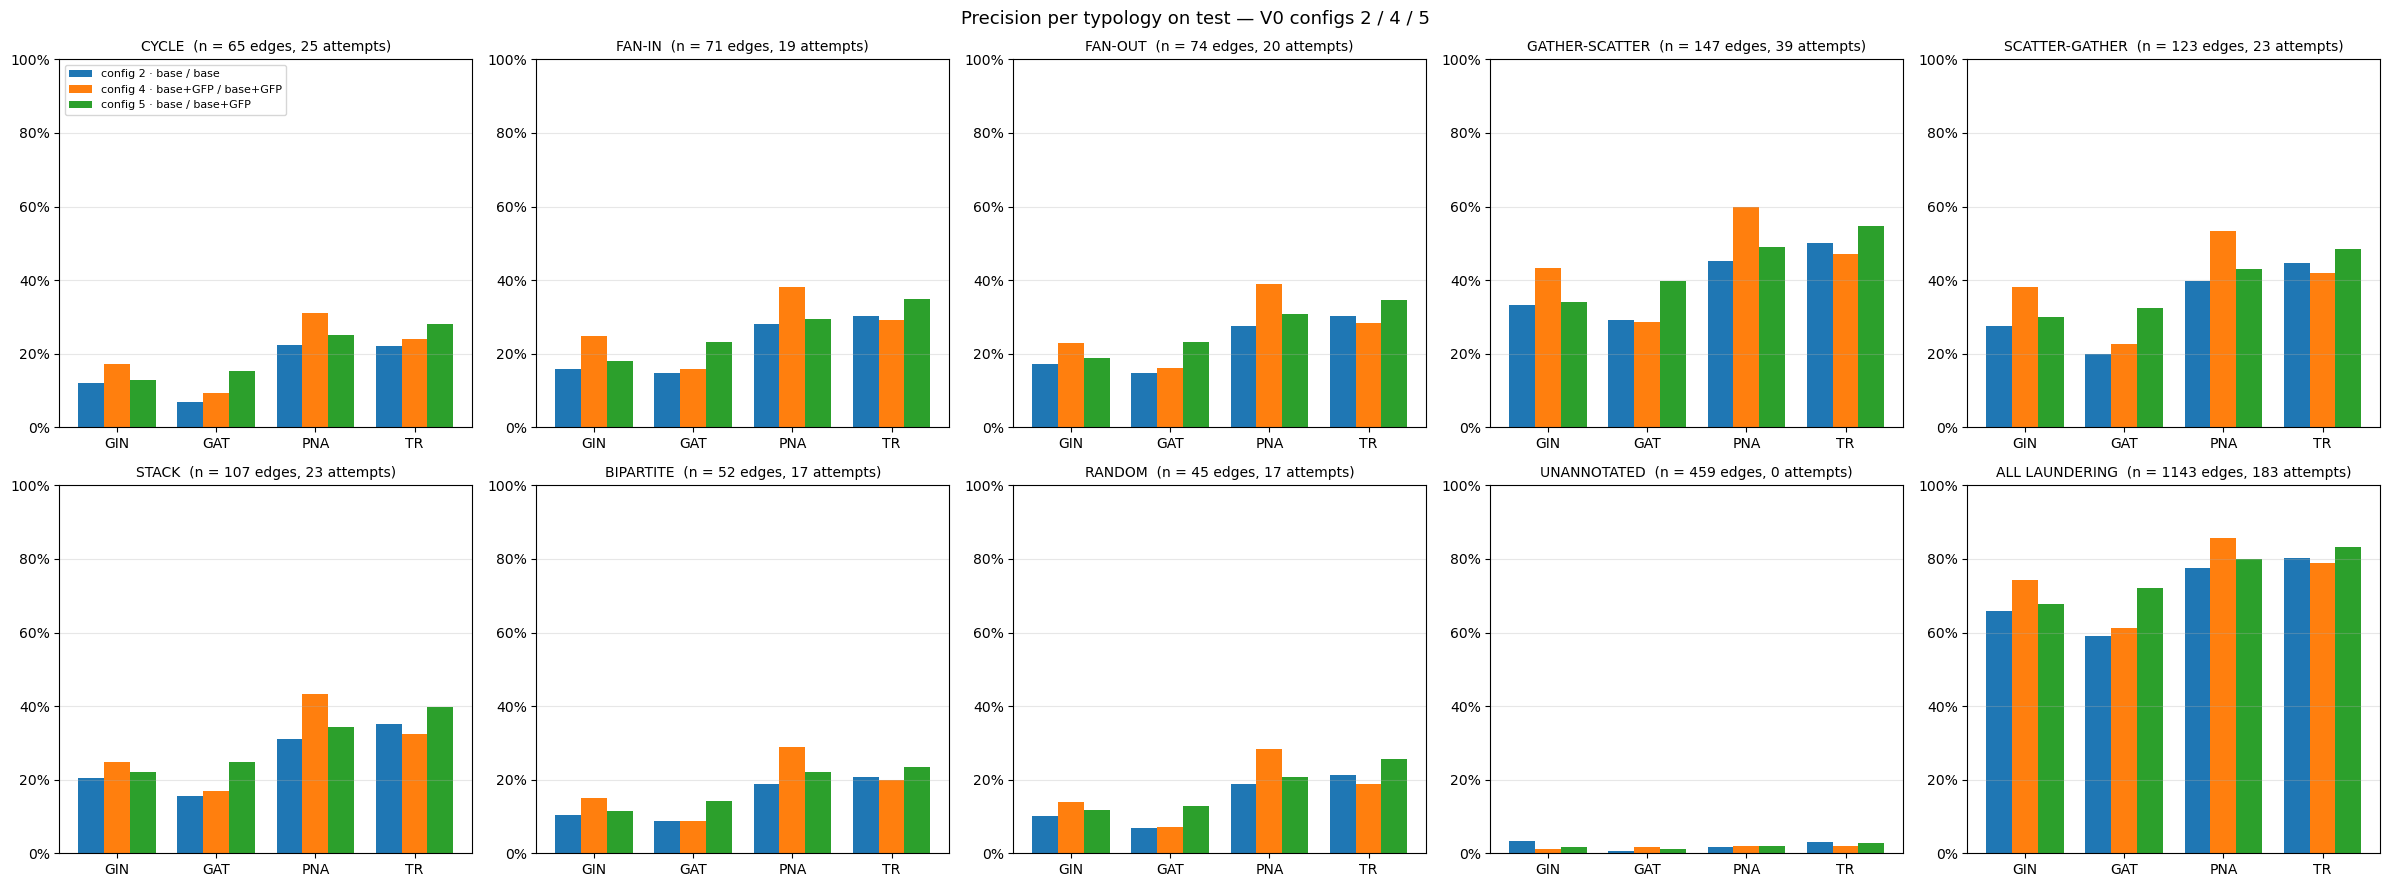

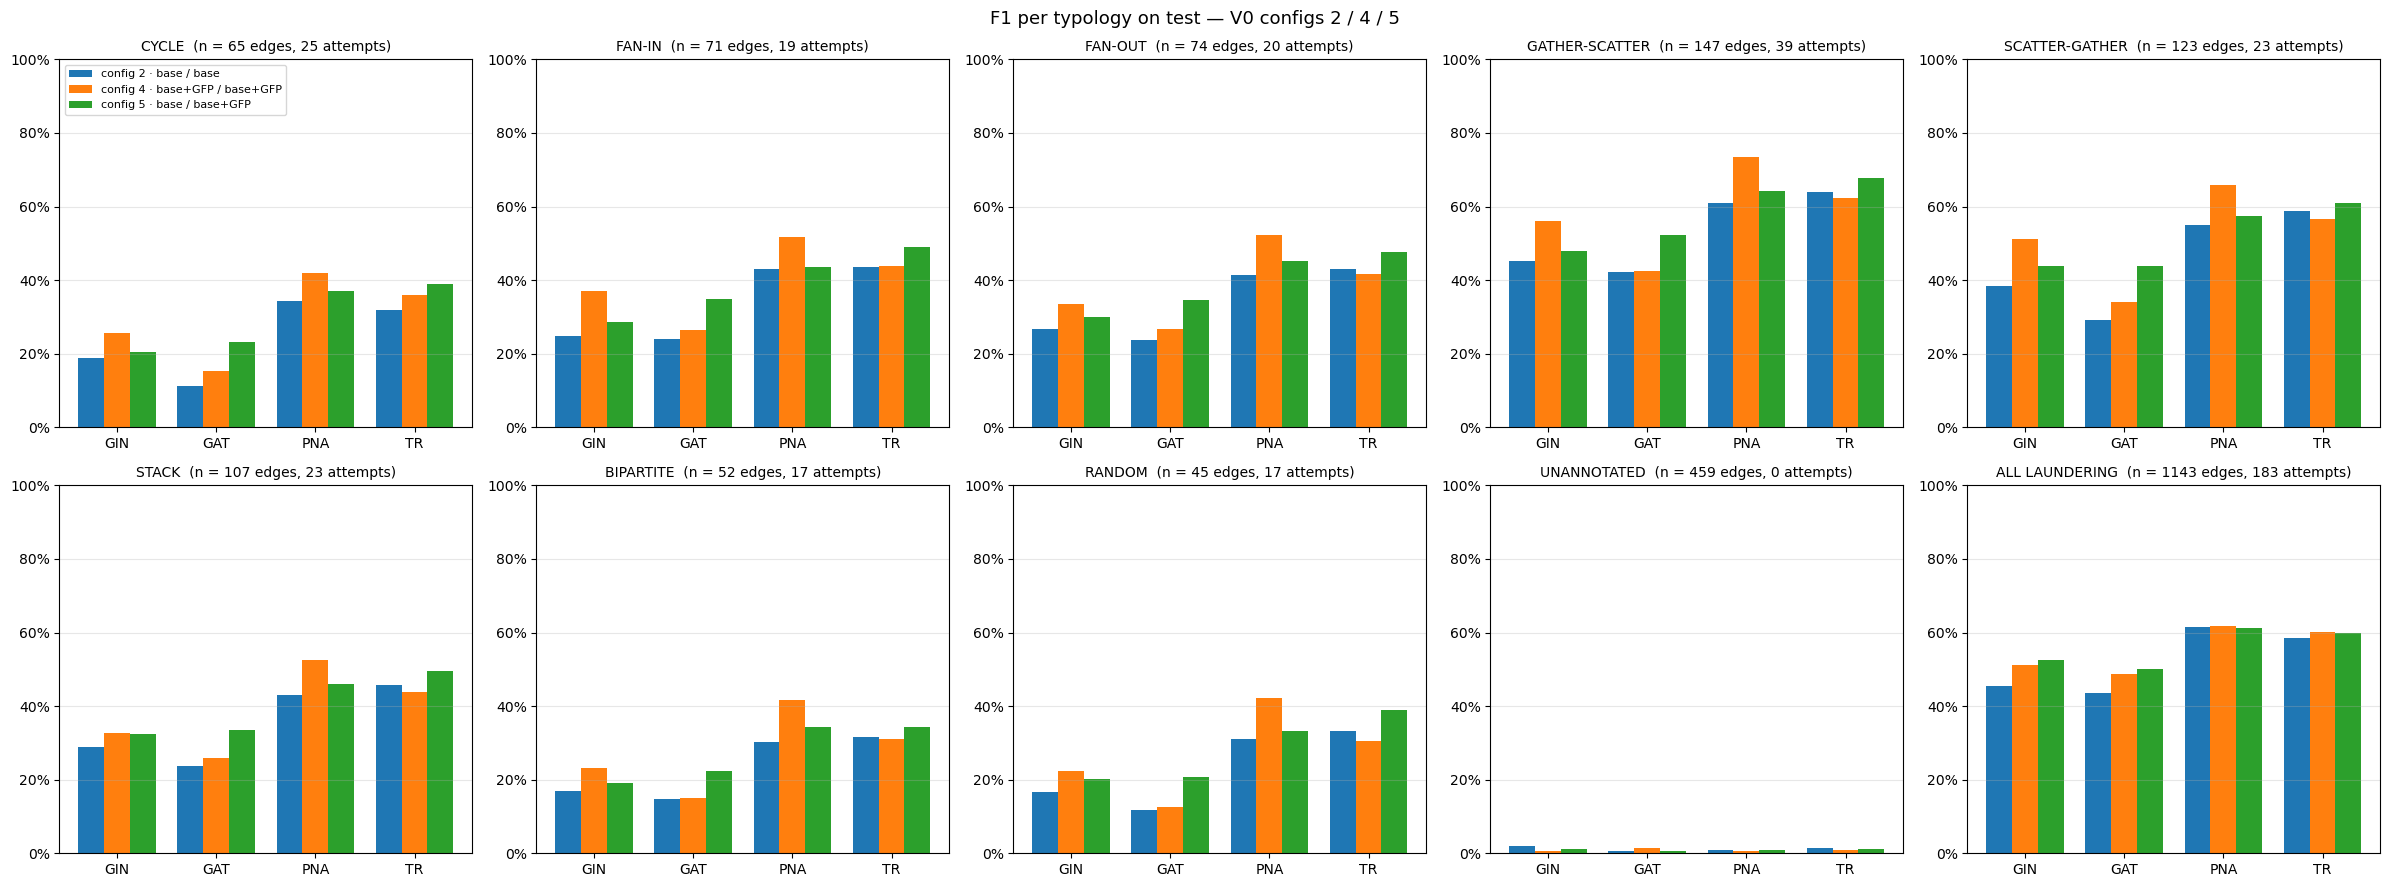

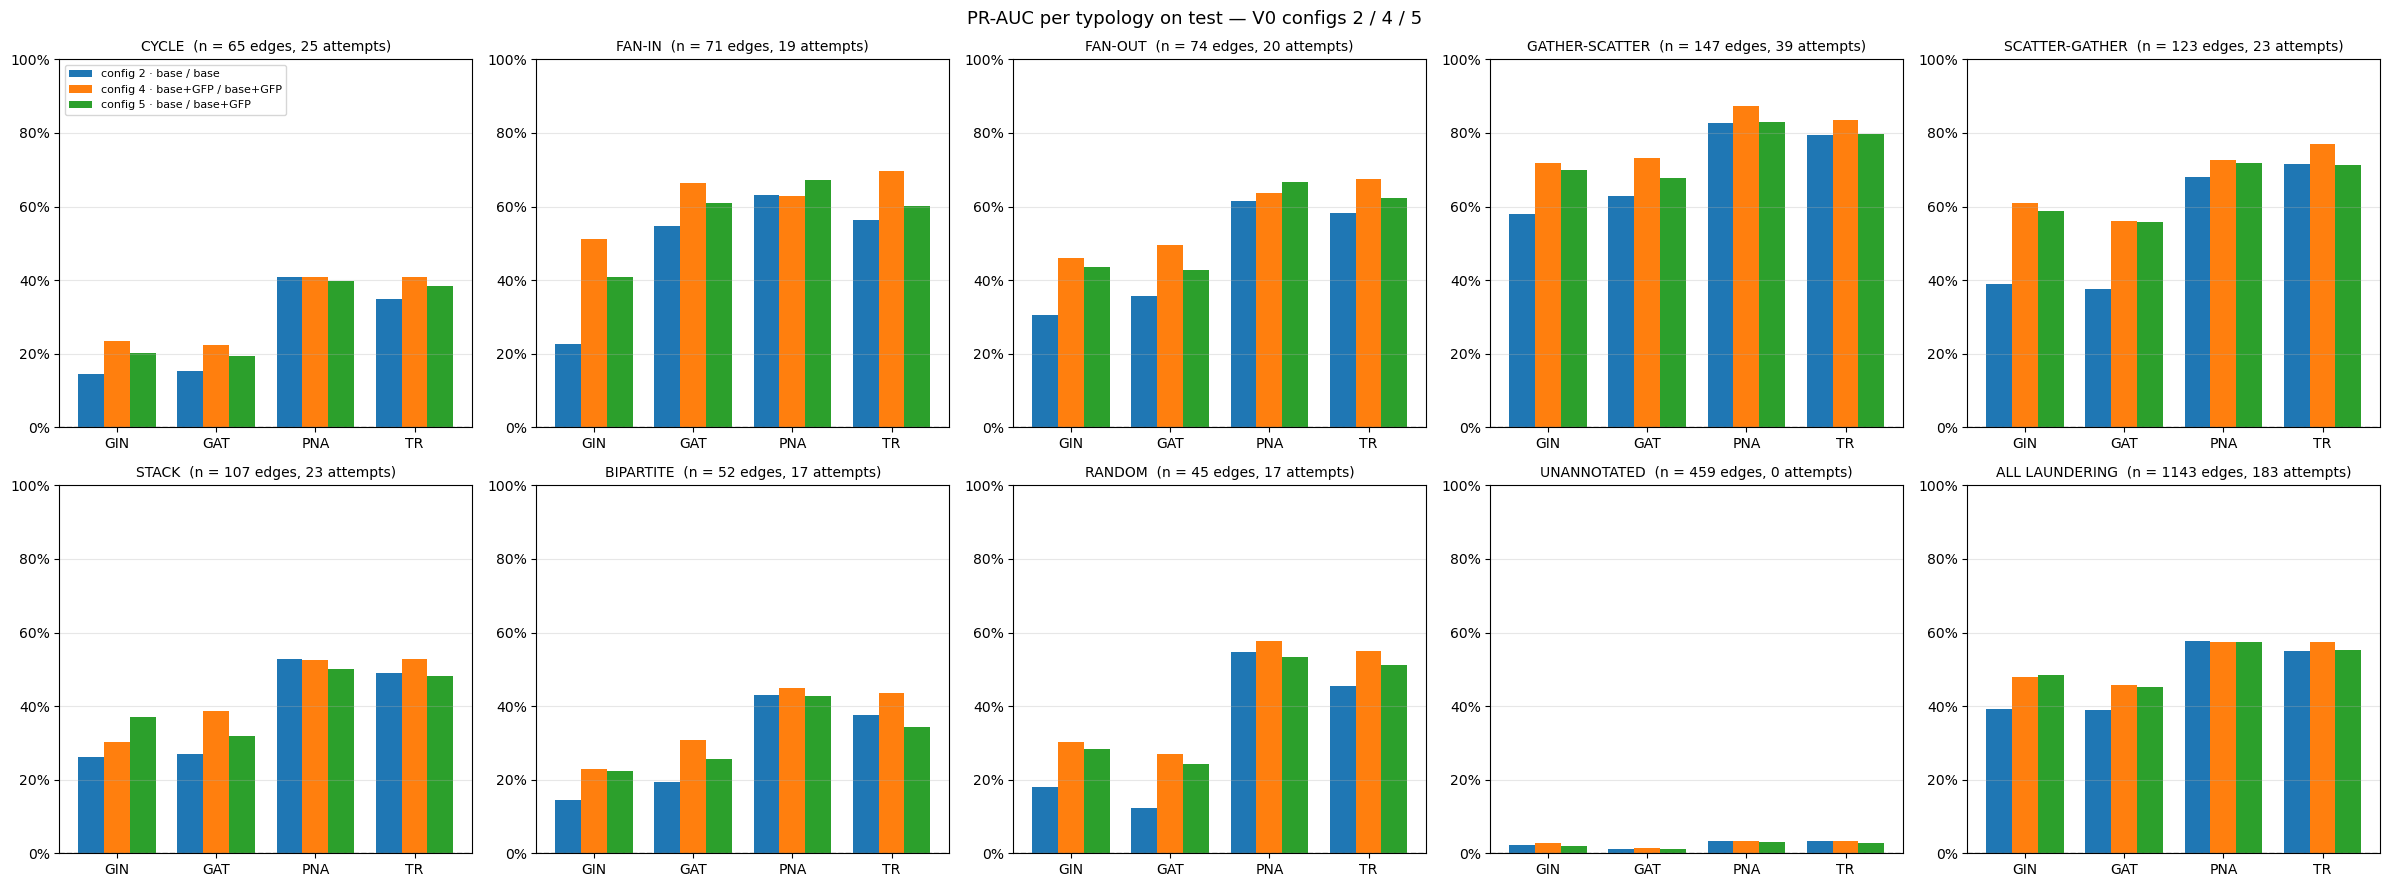

In [17]:
CONFIG_COLOR = {2: '#1f77b4', 4: '#ff7f0e', 5: '#2ca02c'}
CONFIG_NAME = {2: 'config 2 · base / base', 4: 'config 4 · base+GFP / base+GFP', 5: 'config 5 · base / base+GFP'}
METRIC_TITLE = {'recall': 'Recall', 'precision': 'Precision', 'f1': 'F1', 'pr_auc': 'PR-AUC',
                'recall_at_1pct': 'Recall@1 %', 'recall_at_5pct': 'Recall@5 %', 'attempt_recall': 'Attempt recall'}


def bar_chart(metric, filename):
    fig, axes = plt.subplots(2, 5, figsize=(24, 9))
    x, width = np.arange(len(FAMILY_ORDER)), 0.26
    for ax, typology in zip(axes.ravel(), ROWS):
        sub = headline[headline['typology'] == typology]
        for j, config in enumerate(HEADLINE):
            table = sub[sub['config'] == config].set_index('family').reindex(FAMILY_ORDER)
            ax.bar(x + (j - 1) * width, table[metric], width, color=CONFIG_COLOR[config], label=CONFIG_NAME[config])
        if metric == 'pr_auc':
            ax.axhline(sub['pr_auc_random'].iloc[0], ls='--', color='grey', lw=1)
        n_edges, n_attempts = sub['n_test_edges'].iloc[0], sub['n_test_attempts'].iloc[0]
        ax.set_title(f'{typology}  (n = {n_edges} edges, {n_attempts} attempts)', fontsize=10)
        ax.set_xticks(x)
        ax.set_xticklabels(FAMILY_ORDER)
        ax.set_ylim(0, 1)   # same scale in every panel and every chart
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        ax.grid(axis='y', alpha=0.3)
    axes[0, 0].legend(fontsize=8, loc='upper left')
    fig.suptitle(f'{METRIC_TITLE[metric]} per typology on test — V0 configs 2 / 4 / 5', fontsize=13)
    fig.tight_layout()
    fig.savefig(f'{OUT}/{filename}', dpi=120)
    plt.show()


for metric in ('recall', 'precision', 'f1', 'pr_auc'):
    bar_chart(metric, f'bars_{metric}_test.png')

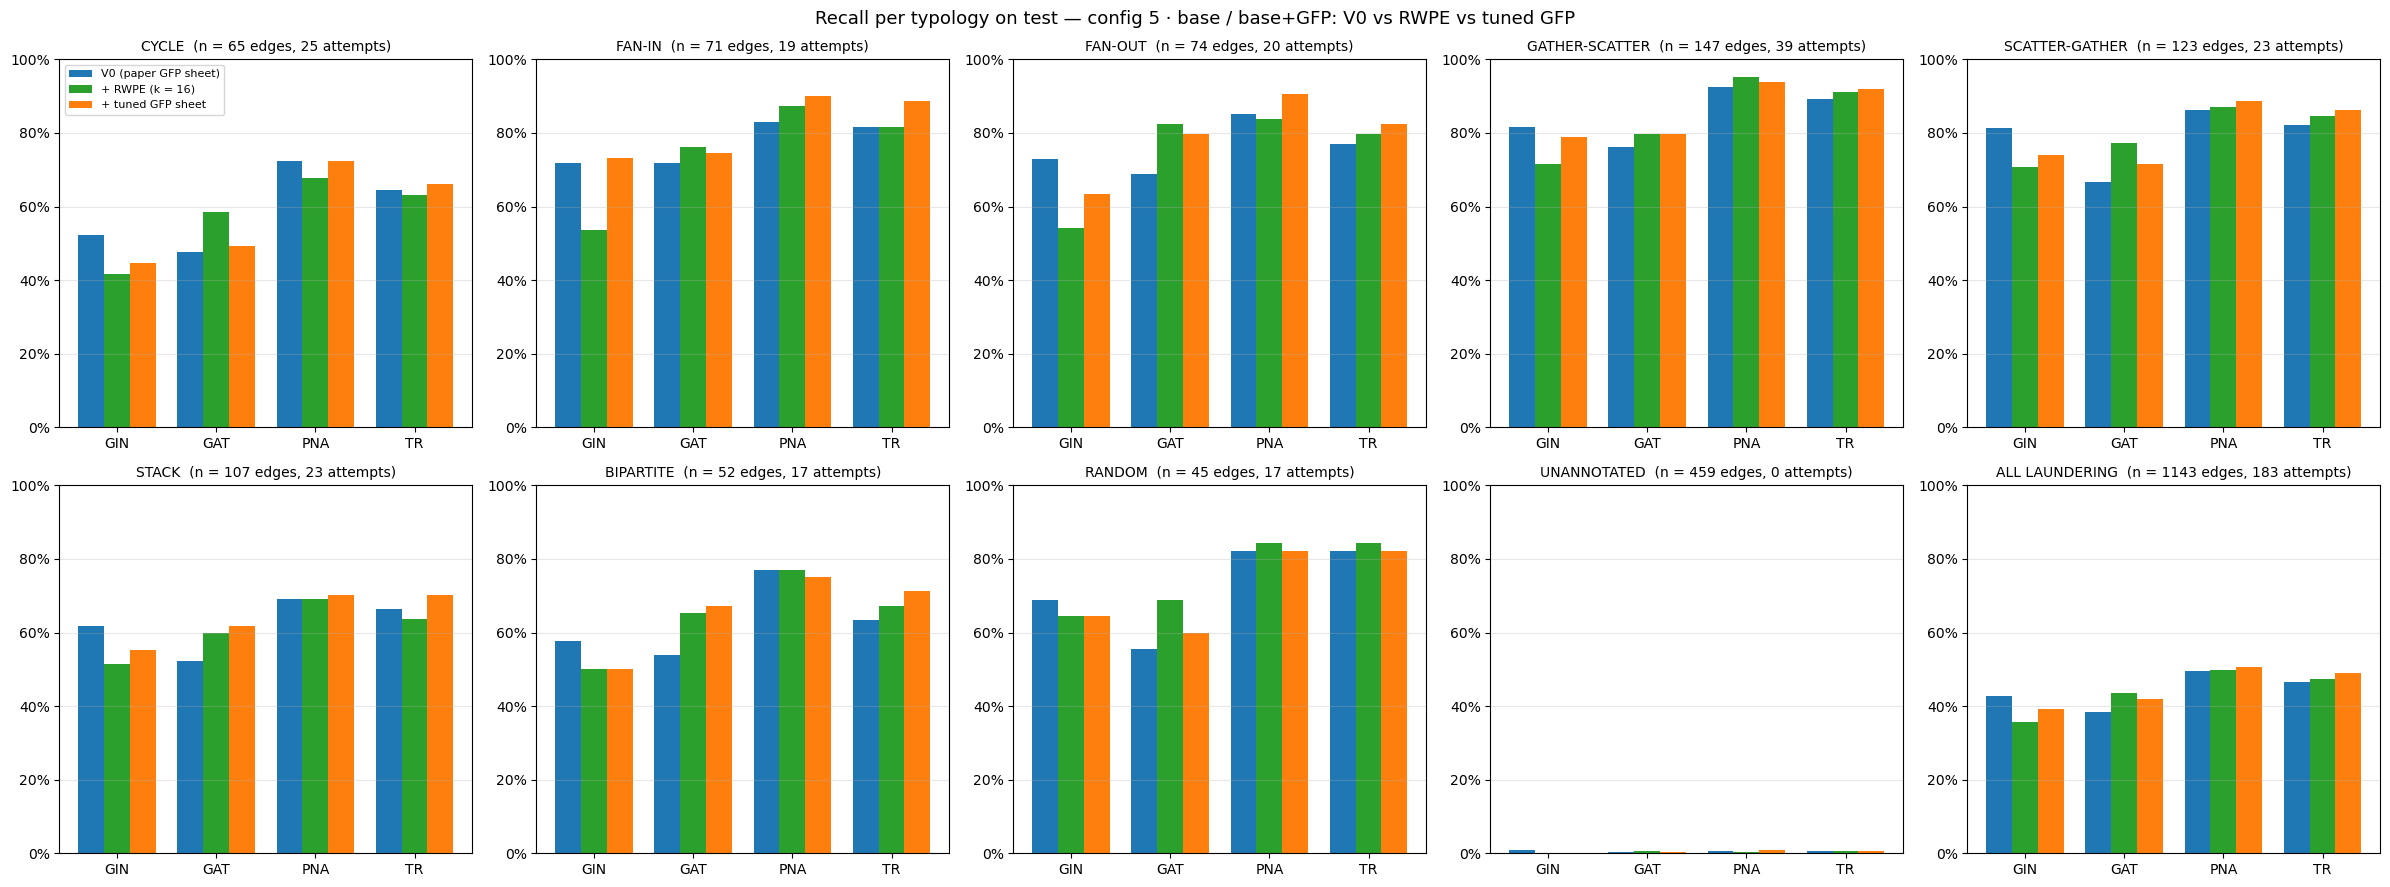

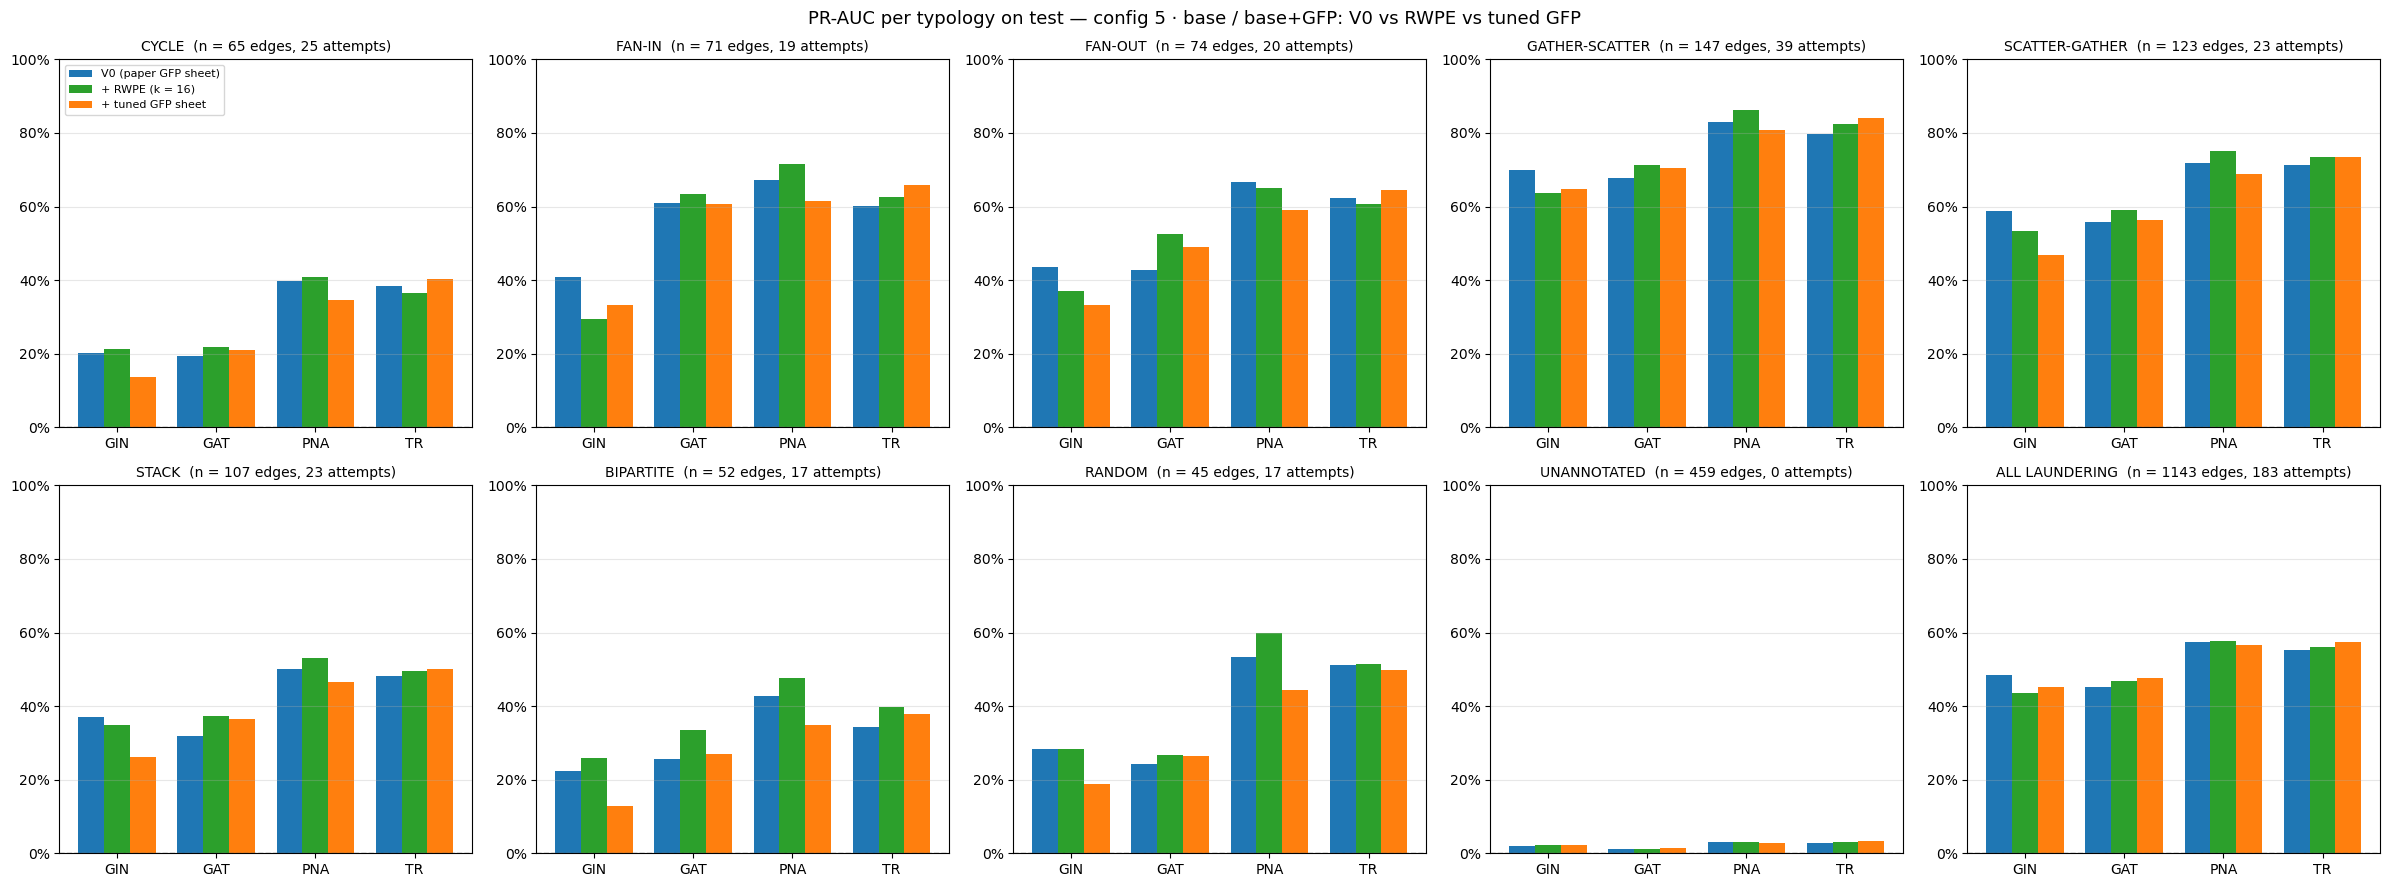

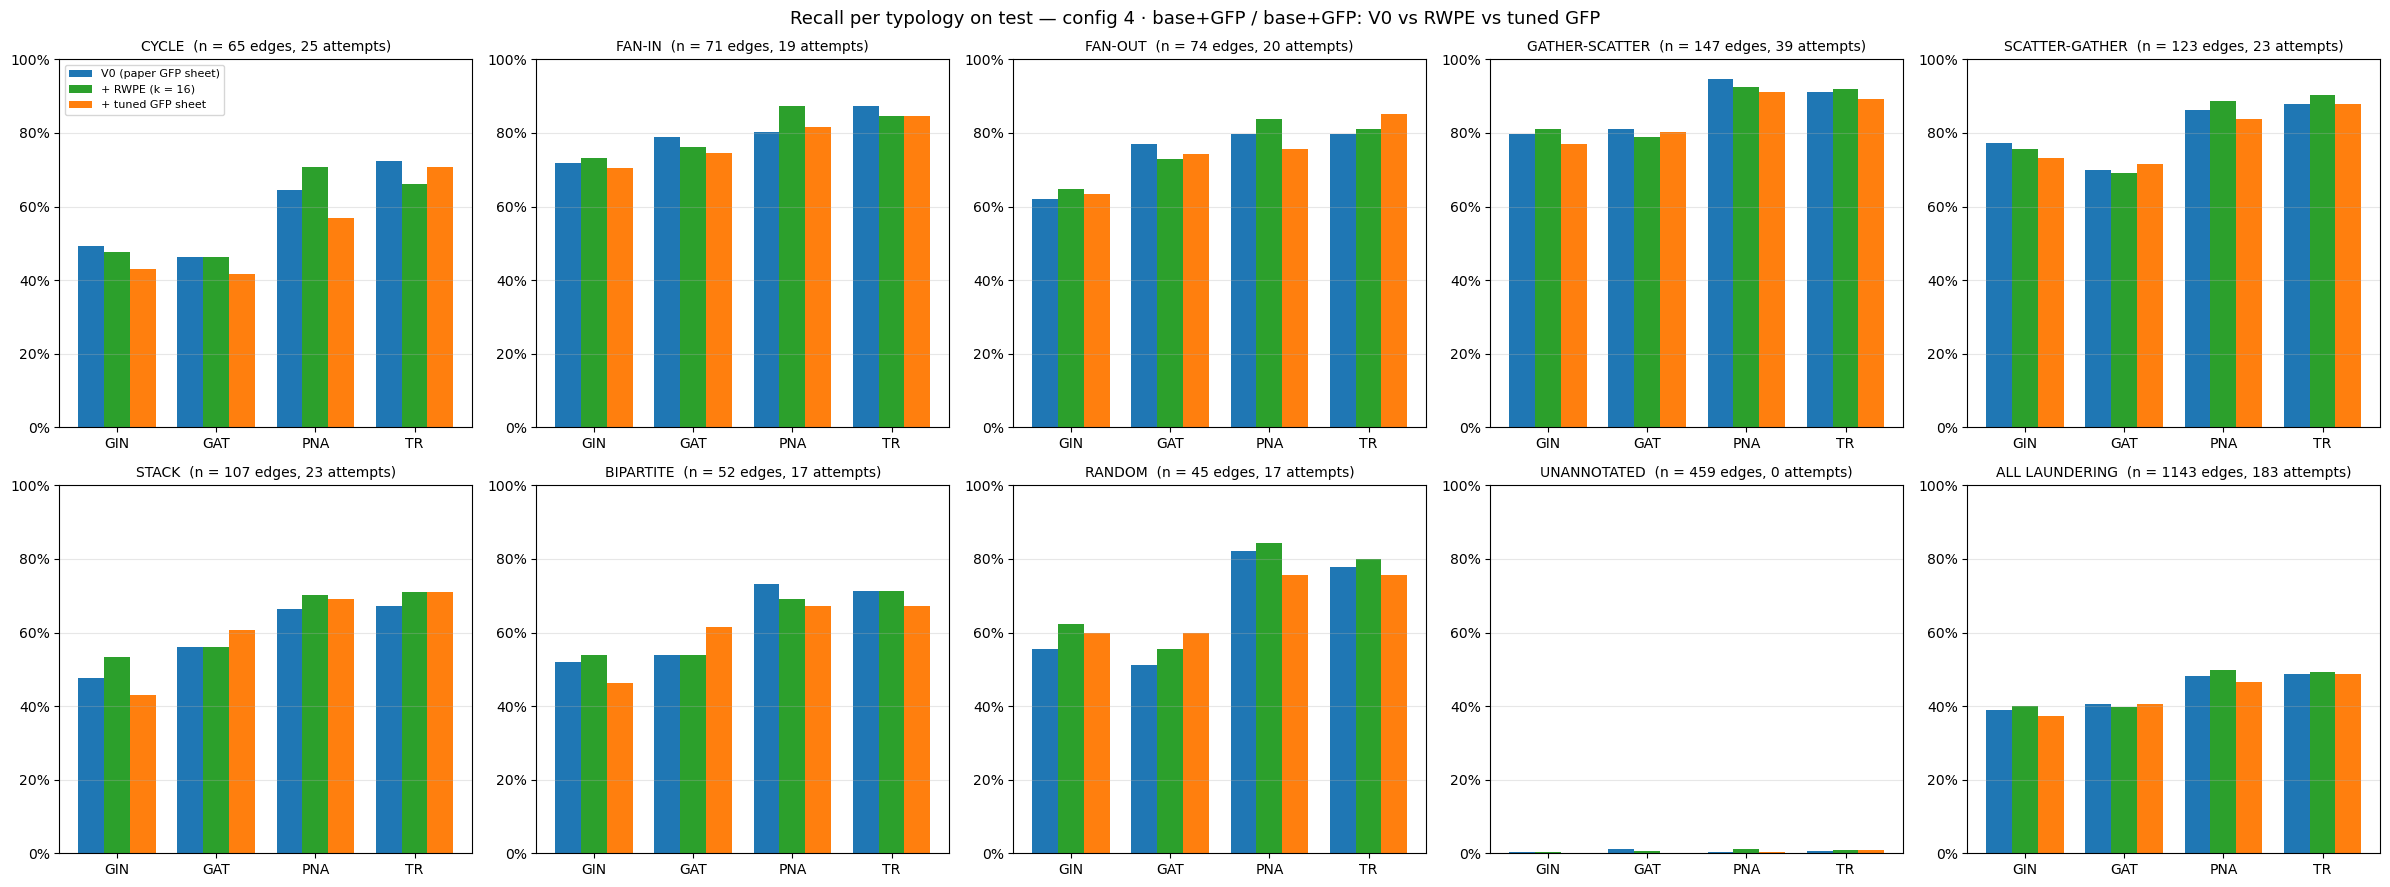

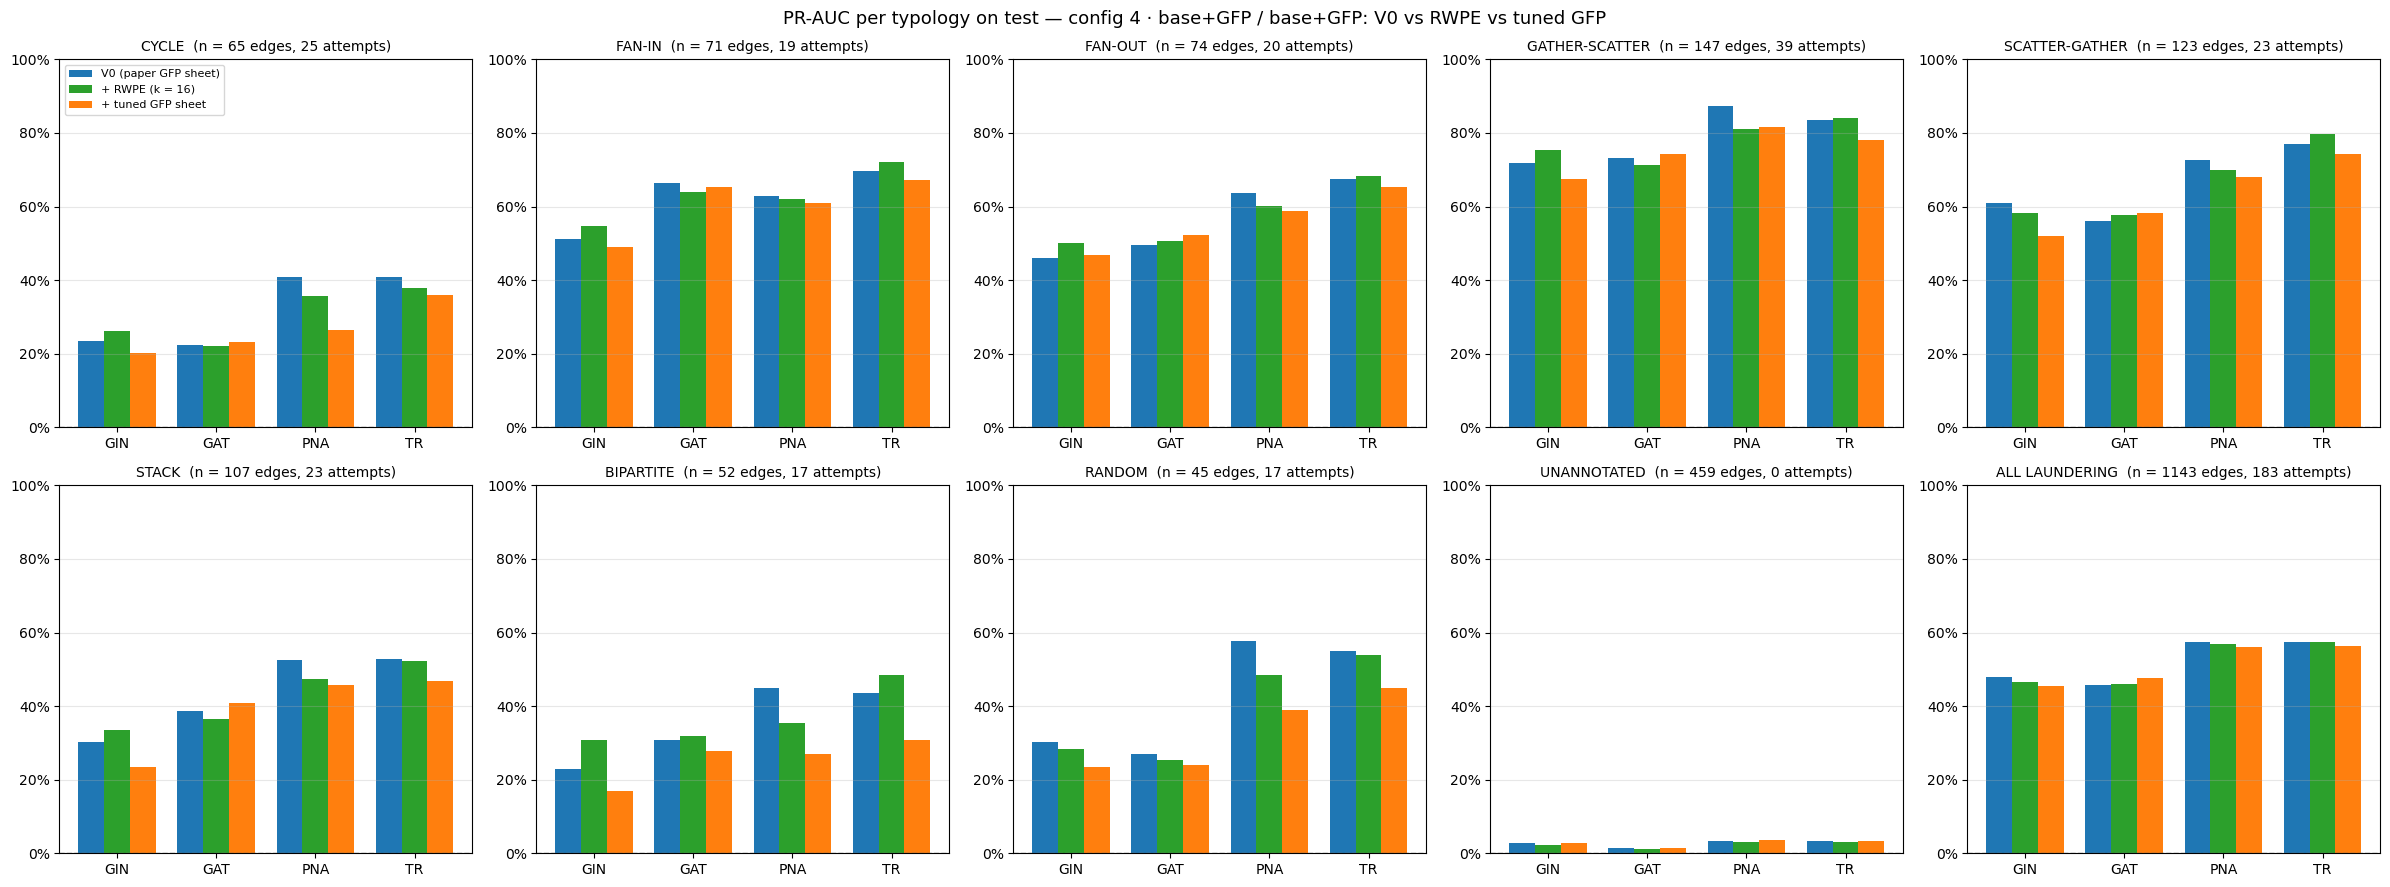

In [18]:
VARIANT_COLOR = {'v0': '#1f77b4', 'rwpe16': '#2ca02c', 'tuned': '#ff7f0e'}
VARIANT_NAME = {'v0': 'V0 (paper GFP sheet)', 'rwpe16': '+ RWPE (k = 16)', 'tuned': '+ tuned GFP sheet'}


def variant_bar_chart(metric, config, filename):
    '''Per typology: each operator with three bars, V0 vs + RWPE vs + tuned, for one feature config.'''
    fig, axes = plt.subplots(2, 5, figsize=(24, 9))
    x, width = np.arange(len(FAMILY_ORDER)), 0.26
    subset = metrics[metrics['config'] == config]
    for ax, typology in zip(axes.ravel(), ROWS):
        sub = subset[subset['typology'] == typology]
        for j, variant in enumerate(VARIANT_ORDER):
            table = sub[sub['variant'] == variant].set_index('family').reindex(FAMILY_ORDER)
            ax.bar(x + (j - 1) * width, table[metric], width, color=VARIANT_COLOR[variant], label=VARIANT_NAME[variant])
        if metric == 'pr_auc':
            ax.axhline(sub['pr_auc_random'].iloc[0], ls='--', color='grey', lw=1)
        n_edges, n_attempts = sub['n_test_edges'].iloc[0], sub['n_test_attempts'].iloc[0]
        ax.set_title(f'{typology}  (n = {n_edges} edges, {n_attempts} attempts)', fontsize=10)
        ax.set_xticks(x)
        ax.set_xticklabels(FAMILY_ORDER)
        ax.set_ylim(0, 1)   # same scale in every panel and every chart
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        ax.grid(axis='y', alpha=0.3)
    axes[0, 0].legend(fontsize=8, loc='upper left')
    fig.suptitle(f'{METRIC_TITLE[metric]} per typology on test — {CONFIG_NAME[config]}: V0 vs RWPE vs tuned GFP', fontsize=13)
    fig.tight_layout()
    fig.savefig(f'{OUT}/{filename}', dpi=120)
    plt.show()


for config in (5, 4):
    for metric in ('recall', 'pr_auc'):
        variant_bar_chart(metric, config, f'bars_variants_{metric}_config{config}_test.png')

# Part B — appendix: uncertainty and diagnostics

- Material for the discussion chapter, not for the main result: how stable the Part A numbers are under resampling, whether attempts that started before the test window are easier, and paired comparisons between runs (feature configs, RWPE, tuned GFP).
- Everything here reuses the per-run arrays of Part A; no file is read again.

## 9. Attempt bootstrap — intervals for the Part A table

- Uncertainty from resampling **attempts** (1,000 draws, seed 42): an attempt brings all its test edges; unannotated edges are their own unit; ALL LAUNDERING mixes both. The normal edges stay fixed and complete, nothing is re-tuned.
- The draws are generated once per typology and reused for every run, so differences between runs in sections 11–12 are paired.
- PR-AUC per draw is computed from each positive's rank among the fixed normal scores (exact; the unweighted case must equal the sklearn value of Part A).
- Output: `typology_metrics_test_intervals.csv` (the Part A metrics with 95 % percentile intervals) and the per-draw values in `bootstrap_draws_test.npz` (not versioned).

In [19]:
B = 1_000
SEED = 42

# fresh = every in-window edge of the attempt is in test (used in section 10)
attempt_split_sets = annotated.groupby('attempt_id')['split'].agg(set)
fresh_attempts = set(attempt_split_sets.index[attempt_split_sets.apply(lambda s: s == {'test'})])
test_edges['fresh'] = test_edges['attempt_id'].isin(fresh_attempts)
assert len(fresh_attempts) == 88   # the "test only" column of section 4


def build_typology(typology):
    '''Test edges of one typology and their bootstrap units (an attempt, or the edge itself when unannotated).'''
    rows = test_edges.loc[typology_rows[typology]]
    attempt = rows['attempt_id'].astype(float).to_numpy()
    unit = np.where(np.isnan(attempt), -(rows['edge_id'].to_numpy() + 1), np.nan_to_num(attempt)).astype(np.int64)
    unit_ids, unit_of_edge = np.unique(unit, return_inverse=True)
    membership = np.zeros((len(unit_ids), len(rows)), dtype=np.int64)   # unit x edge
    membership[unit_of_edge, np.arange(len(rows))] = 1
    is_attempt = unit_ids >= 0
    return {'idx': rows.index.to_numpy(), 'membership': membership, 'is_attempt': is_attempt,
            'fresh_unit': np.isin(unit_ids, list(fresh_attempts)), 'fresh_edge': rows['fresh'].to_numpy(),
            'annotated_edge': ~np.isnan(attempt), 'n_edges': len(rows), 'n_units': len(unit_ids),
            'n_attempts': int(is_attempt.sum())}


typologies = {typology: build_typology(typology) for typology in ROWS}

# shared draws: unit counts per draw (B x units) and the resulting edge weights (B x edges), once per typology
rng = np.random.default_rng(SEED)
for typology in ROWS:
    t = typologies[typology]
    samples = rng.integers(0, t['n_units'], size=(B, t['n_units']))
    unit_counts = np.zeros((B, t['n_units']), dtype=np.int64)
    np.add.at(unit_counts, (np.repeat(np.arange(B), t['n_units']), samples.ravel()), 1)
    t['U'] = unit_counts
    t['W'] = unit_counts @ t['membership']
    assert (t['U'].sum(1) == t['n_units']).all() and (t['W'].sum(1) >= 1).all()

units_table = pd.DataFrame({typology: {'test_edges': t['n_edges'], 'bootstrap_units': t['n_units'],
                                       'attempts': t['n_attempts'], 'fresh_attempts': int(t['fresh_unit'].sum())}
                            for typology, t in typologies.items()}).T
assert units_table.loc['ALL LAUNDERING', 'test_edges'] == 1_143
print(f'{B} shared bootstrap draws per typology (seed {SEED})')
display(units_table)

1000 shared bootstrap draws per typology (seed 42)


,test_edges,bootstrap_units,attempts,fresh_attempts
CYCLE,65,25,25,10
FAN-IN,71,19,19,12
FAN-OUT,74,20,20,10
GATHER-SCATTER,147,39,39,16
SCATTER-GATHER,123,23,23,11
STACK,107,23,23,4
BIPARTITE,52,17,17,13
RANDOM,45,17,17,12
UNANNOTATED,459,459,0,0
ALL LAUNDERING,1143,642,183,88


In [20]:
def weighted_metrics(W, U, sub, fp, caught, is_attempt):
    '''All seven metrics for every row of W (edge weights) / U (unit counts); W = ones gives the point estimate.

    sub: prob, pred, top1, top5, n_legit_ge of T's edges; fp: false positives of the split;
    caught: per unit, >= 1 flagged edge. PR-AUC: sum over positives of weight x precision at that positive's
    score, where precision = W(score >= p) / (W(score >= p) + normal edges with score >= p).
    '''
    total = W.sum(1)
    tp = W @ sub['pred']
    with np.errstate(divide='ignore', invalid='ignore'):
        recall = tp / total
        precision = tp / (tp + fp)
        f1 = np.where(tp > 0, 2 * precision * recall / (precision + recall), 0.0)
        order = np.argsort(-sub['prob'], kind='stable')
        p_sorted = sub['prob'][order]
        n_ge = np.searchsorted(-p_sorted, -p_sorted, side='right')     # edges of T with score >= this one (ties included)
        W_sorted = W[:, order]
        W_ge = np.cumsum(W_sorted, axis=1)[:, n_ge - 1]
        pr_auc = (W_sorted * W_ge / (W_ge + sub['n_legit_ge'][order])).sum(1) / total
        if is_attempt.any():
            U_att = U[:, is_attempt]
            attempt_recall = (U_att @ caught[is_attempt]) / U_att.sum(1)
        else:
            attempt_recall = np.full(len(W), np.nan)
    return {'recall': recall, 'precision': precision, 'f1': f1, 'pr_auc': pr_auc,
            'recall_at_1pct': (W @ sub['top1']) / total, 'recall_at_5pct': (W @ sub['top5']) / total,
            'attempt_recall': attempt_recall}


def interval(values):
    '''95 % percentile interval of one metric's bootstrap draws (nan, nan when the metric is undefined).'''
    if np.all(np.isnan(values)):
        return (np.nan, np.nan)
    return tuple(np.nanpercentile(values, [2.5, 97.5]))

In [21]:
point, draws, interval_rows = {}, {}, []
plain = metrics.set_index(['label', 'typology'])
tic = time.time()
for label, data in run_data.items():
    for typology in ROWS:
        t = typologies[typology]
        sub = {key: data[key][t['idx']] for key in ('prob', 'pred', 'top1', 'top5', 'n_legit_ge')}
        caught = (t['membership'] @ sub['pred']) > 0
        pt = weighted_metrics(np.ones((1, t['n_edges']), dtype=np.int64), np.ones((1, t['n_units']), dtype=np.int64),
                              sub, data['fp'], caught, t['is_attempt'])
        bs = weighted_metrics(t['W'], t['U'], sub, data['fp'], caught, t['is_attempt'])
        row = plain.loc[(label, typology)]
        for name in METRIC_NAMES:   # the unweighted bootstrap formulas must give the Part A numbers
            assert (np.isnan(pt[name][0]) and np.isnan(row[name])) or abs(pt[name][0] - row[name]) < 1e-8, (label, typology, name)
        point[(label, typology)] = {name: float(row[name]) for name in METRIC_NAMES}
        draws[(label, typology)] = {name: bs[name].astype(np.float32) for name in METRIC_NAMES}
        out = {'label': label, 'typology': typology}
        for name in METRIC_NAMES:
            out[name] = float(row[name])
            out[f'{name}_lo'], out[f'{name}_hi'] = interval(bs[name])
        interval_rows.append(out)

intervals = metrics[['run', 'label', 'family', 'config', 'variant', 'headline', 'typology', 'n_test_edges', 'n_test_attempts']].merge(
    pd.DataFrame(interval_rows), on=['label', 'typology'], how='left')
assert len(intervals) == 44 * len(ROWS) and intervals['recall_lo'].notna().all()
intervals.to_csv(f'{OUT}/typology_metrics_test_intervals.csv', index=False)
np.savez_compressed(f'{OUT}/bootstrap_draws_test.npz',
                    **{f'{label}__{typology}__{name}': values
                       for (label, typology), per_metric in draws.items() for name, values in per_metric.items()})
print(f'{len(intervals)} rows -> {OUT}/typology_metrics_test_intervals.csv | per-draw values -> {OUT}/bootstrap_draws_test.npz '
      f'({time.time() - tic:.0f} s)')


def show_ci(metric, subset, columns='label'):
    '''typology x run table of one metric formatted "value [lo, hi]".'''
    text = subset.apply(lambda r: f'{r[metric]:.2f} [{r[f"{metric}_lo"]:.2f}, {r[f"{metric}_hi"]:.2f}]', axis=1)
    return subset.assign(cell=text).pivot(index='typology', columns=columns, values='cell').reindex(ROWS)


headline_ci = intervals[intervals['label'].isin(labels_headline)]
for metric in ('recall', 'pr_auc'):
    print(f'\n{metric} on test with 95 % bootstrap intervals, V0 configs 2 / 4 / 5')
    display(show_ci(metric, headline_ci)[labels_headline])

440 rows -> Outputs/TYPOLOGY/typology_metrics_test_intervals.csv | per-draw values -> Outputs/TYPOLOGY/bootstrap_draws_test.npz (8 s)

recall on test with 95 % bootstrap intervals, V0 configs 2 / 4 / 5


label,GIN-2,GIN-4,GIN-5,GAT-2,GAT-4,GAT-5,PNA-2,PNA-4,PNA-5,TR-2,TR-4,TR-5
typology,,,,,,,,,,,,
CYCLE,"0.43 [0.29, 0.61]","0.49 [0.35, 0.65]","0.52 [0.36, 0.70]","0.31 [0.16, 0.47]","0.46 [0.33, 0.59]","0.48 [0.34, 0.64]","0.74 [0.60, 0.88]","0.65 [0.50, 0.80]","0.72 [0.56, 0.88]","0.57 [0.40, 0.75]","0.72 [0.59, 0.85]","0.65 [0.49, 0.80]"
FAN-IN,"0.55 [0.40, 0.68]","0.72 [0.53, 0.84]","0.72 [0.54, 0.84]","0.66 [0.45, 0.81]","0.79 [0.63, 0.90]","0.72 [0.56, 0.83]","0.92 [0.82, 0.98]","0.80 [0.63, 0.92]","0.83 [0.74, 0.91]","0.79 [0.65, 0.90]","0.87 [0.70, 0.98]","0.82 [0.65, 0.93]"
FAN-OUT,"0.58 [0.36, 0.79]","0.62 [0.42, 0.80]","0.73 [0.59, 0.85]","0.64 [0.46, 0.80]","0.77 [0.64, 0.88]","0.69 [0.52, 0.83]","0.85 [0.75, 0.93]","0.80 [0.66, 0.90]","0.85 [0.74, 0.94]","0.76 [0.62, 0.86]","0.80 [0.64, 0.92]","0.77 [0.61, 0.90]"
GATHER-SCATTER,"0.70 [0.57, 0.82]","0.80 [0.69, 0.88]","0.82 [0.72, 0.89]","0.77 [0.68, 0.85]","0.81 [0.74, 0.87]","0.76 [0.68, 0.83]","0.94 [0.89, 0.98]","0.95 [0.90, 0.98]","0.93 [0.88, 0.96]","0.88 [0.80, 0.95]","0.91 [0.85, 0.97]","0.89 [0.83, 0.95]"
SCATTER-GATHER,"0.63 [0.50, 0.76]","0.77 [0.67, 0.85]","0.81 [0.72, 0.89]","0.55 [0.47, 0.63]","0.70 [0.62, 0.77]","0.67 [0.58, 0.76]","0.89 [0.81, 0.96]","0.86 [0.78, 0.93]","0.86 [0.78, 0.94]","0.85 [0.75, 0.93]","0.88 [0.78, 0.94]","0.82 [0.70, 0.91]"
STACK,"0.50 [0.38, 0.61]","0.48 [0.37, 0.58]","0.62 [0.52, 0.70]","0.48 [0.35, 0.59]","0.56 [0.44, 0.66]","0.52 [0.40, 0.63]","0.70 [0.54, 0.84]","0.66 [0.53, 0.79]","0.69 [0.53, 0.82]","0.65 [0.53, 0.77]","0.67 [0.53, 0.79]","0.66 [0.55, 0.76]"
BIPARTITE,"0.46 [0.30, 0.68]","0.52 [0.34, 0.72]","0.58 [0.35, 0.84]","0.50 [0.27, 0.73]","0.54 [0.34, 0.76]","0.54 [0.32, 0.75]","0.75 [0.62, 0.90]","0.73 [0.58, 0.88]","0.77 [0.60, 0.92]","0.65 [0.51, 0.84]","0.71 [0.49, 0.90]","0.63 [0.44, 0.83]"
RANDOM,"0.51 [0.34, 0.68]","0.56 [0.40, 0.72]","0.69 [0.54, 0.82]","0.44 [0.32, 0.58]","0.51 [0.38, 0.64]","0.56 [0.42, 0.68]","0.87 [0.78, 0.95]","0.82 [0.71, 0.93]","0.82 [0.73, 0.92]","0.78 [0.67, 0.90]","0.78 [0.67, 0.89]","0.82 [0.73, 0.92]"
UNANNOTATED,"0.02 [0.00, 0.03]","0.00 [0.00, 0.01]","0.01 [0.00, 0.02]","0.00 [0.00, 0.01]","0.01 [0.00, 0.02]","0.00 [0.00, 0.01]","0.01 [0.00, 0.02]","0.00 [0.00, 0.01]","0.01 [0.00, 0.02]","0.01 [0.00, 0.02]","0.01 [0.00, 0.02]","0.01 [0.00, 0.02]"



pr_auc on test with 95 % bootstrap intervals, V0 configs 2 / 4 / 5


label,GIN-2,GIN-4,GIN-5,GAT-2,GAT-4,GAT-5,PNA-2,PNA-4,PNA-5,TR-2,TR-4,TR-5
typology,,,,,,,,,,,,
CYCLE,"0.14 [0.06, 0.29]","0.23 [0.11, 0.41]","0.20 [0.10, 0.37]","0.15 [0.09, 0.32]","0.22 [0.13, 0.42]","0.19 [0.12, 0.35]","0.41 [0.28, 0.57]","0.41 [0.27, 0.58]","0.40 [0.30, 0.57]","0.35 [0.22, 0.55]","0.41 [0.28, 0.59]","0.38 [0.27, 0.57]"
FAN-IN,"0.23 [0.12, 0.33]","0.51 [0.30, 0.66]","0.41 [0.25, 0.54]","0.55 [0.40, 0.71]","0.66 [0.47, 0.80]","0.61 [0.44, 0.74]","0.63 [0.47, 0.74]","0.63 [0.44, 0.75]","0.67 [0.56, 0.79]","0.56 [0.37, 0.70]","0.70 [0.49, 0.81]","0.60 [0.40, 0.72]"
FAN-OUT,"0.31 [0.11, 0.52]","0.46 [0.24, 0.66]","0.44 [0.25, 0.62]","0.36 [0.22, 0.52]","0.50 [0.35, 0.67]","0.43 [0.27, 0.60]","0.61 [0.45, 0.73]","0.64 [0.49, 0.79]","0.67 [0.53, 0.79]","0.58 [0.42, 0.73]","0.67 [0.51, 0.82]","0.62 [0.45, 0.77]"
GATHER-SCATTER,"0.58 [0.44, 0.71]","0.72 [0.60, 0.82]","0.70 [0.59, 0.80]","0.63 [0.53, 0.73]","0.73 [0.65, 0.80]","0.68 [0.59, 0.76]","0.83 [0.77, 0.88]","0.87 [0.82, 0.92]","0.83 [0.78, 0.89]","0.80 [0.71, 0.87]","0.84 [0.78, 0.89]","0.80 [0.72, 0.86]"
SCATTER-GATHER,"0.39 [0.26, 0.51]","0.61 [0.47, 0.71]","0.59 [0.47, 0.69]","0.38 [0.28, 0.47]","0.56 [0.46, 0.65]","0.56 [0.45, 0.65]","0.68 [0.56, 0.77]","0.73 [0.61, 0.81]","0.72 [0.63, 0.81]","0.72 [0.62, 0.81]","0.77 [0.67, 0.85]","0.71 [0.61, 0.82]"
STACK,"0.26 [0.17, 0.36]","0.30 [0.20, 0.40]","0.37 [0.27, 0.46]","0.27 [0.18, 0.38]","0.39 [0.27, 0.50]","0.32 [0.22, 0.44]","0.53 [0.37, 0.66]","0.53 [0.40, 0.64]","0.50 [0.34, 0.63]","0.49 [0.38, 0.61]","0.53 [0.42, 0.66]","0.48 [0.38, 0.60]"
BIPARTITE,"0.15 [0.06, 0.29]","0.23 [0.15, 0.38]","0.22 [0.12, 0.38]","0.19 [0.10, 0.38]","0.31 [0.17, 0.47]","0.26 [0.15, 0.43]","0.43 [0.28, 0.58]","0.45 [0.31, 0.59]","0.43 [0.27, 0.59]","0.38 [0.25, 0.55]","0.44 [0.29, 0.59]","0.34 [0.23, 0.50]"
RANDOM,"0.18 [0.10, 0.29]","0.30 [0.18, 0.43]","0.28 [0.18, 0.40]","0.12 [0.07, 0.24]","0.27 [0.19, 0.43]","0.24 [0.17, 0.39]","0.55 [0.42, 0.66]","0.58 [0.44, 0.72]","0.53 [0.41, 0.66]","0.45 [0.32, 0.61]","0.55 [0.42, 0.72]","0.51 [0.41, 0.66]"
UNANNOTATED,"0.02 [0.02, 0.03]","0.03 [0.02, 0.03]","0.02 [0.02, 0.02]","0.01 [0.01, 0.01]","0.01 [0.01, 0.02]","0.01 [0.01, 0.01]","0.03 [0.03, 0.04]","0.03 [0.03, 0.04]","0.03 [0.03, 0.03]","0.03 [0.03, 0.04]","0.03 [0.03, 0.04]","0.03 [0.02, 0.03]"


## 10. Fresh vs continued attempts

- A test attempt is **fresh** when every one of its in-window edges is in test, **continued** when it also has edges in train or val (88 fresh, 95 continued).
- Continued attempts had earlier edges labelled in training, so a typology dominated by them (STACK: 19 of 23 test attempts) may look easier than a new attempt would be. This is not leakage — it is how a temporal split works — but it matters for reading the per-typology numbers.
- Reported for the headline runs (V0 configs 2 / 4 / 5): recall, recall@5 % and attempt recall per group, with counts and intervals from the same paired draws (edge weights restricted to the group). Output: `fresh_vs_continued_test.csv`.

In [22]:
def group_metrics(W, U, sub, edge_mask, unit_mask, caught):
    '''recall, recall@5 % and attempt recall restricted to one group of edges / attempts, per row of W / U.'''
    with np.errstate(divide='ignore', invalid='ignore'):
        total = W @ edge_mask
        U_group = U[:, unit_mask]
        return {'recall': (W @ (sub['pred'] * edge_mask)) / total,
                'recall_at_5pct': (W @ (sub['top5'] * edge_mask)) / total,
                'attempt_recall': (U_group @ caught[unit_mask]) / U_group.sum(1)}


fresh_rows = []
for label in labels_headline:
    data = run_data[label]
    for typology in TYPOLOGIES + ['ALL LAUNDERING']:
        t = typologies[typology]
        sub = {key: data[key][t['idx']] for key in ('pred', 'top5')}
        caught = (t['membership'] @ sub['pred']) > 0
        for group, fresh in (('fresh', True), ('continued', False)):
            edge_mask = (t['annotated_edge'] & (t['fresh_edge'] == fresh)).astype(np.int64)
            unit_mask = t['is_attempt'] & (t['fresh_unit'] == fresh)
            pt = group_metrics(np.ones((1, t['n_edges']), dtype=np.int64), np.ones((1, t['n_units']), dtype=np.int64),
                               sub, edge_mask, unit_mask, caught)
            bs = group_metrics(t['W'], t['U'], sub, edge_mask, unit_mask, caught)
            row = {'label': label, 'typology': 'ALL ANNOTATED' if typology == 'ALL LAUNDERING' else typology,
                   'group': group, 'n_attempts': int(unit_mask.sum()), 'n_test_edges': int(edge_mask.sum())}
            for name in ('recall', 'recall_at_5pct', 'attempt_recall'):
                row[name] = float(pt[name][0])
                row[f'{name}_lo'], row[f'{name}_hi'] = interval(bs[name])
            fresh_rows.append(row)
fresh_table = pd.DataFrame(fresh_rows)
fresh_table.to_csv(f'{OUT}/fresh_vs_continued_test.csv', index=False)
print(f'{len(fresh_table)} rows -> {OUT}/fresh_vs_continued_test.csv')

group_sizes = fresh_table[fresh_table['label'] == labels_headline[0]].pivot(index='typology', columns='group', values=['n_attempts', 'n_test_edges'])
display(group_sizes.reindex(TYPOLOGIES + ['ALL ANNOTATED']))
for name in ('recall', 'attempt_recall'):
    cell = fresh_table.apply(lambda r: f'{r[name]:.2f} [{r[f"{name}_lo"]:.2f}, {r[f"{name}_hi"]:.2f}]' if r['n_attempts'] else '—', axis=1)
    table = fresh_table.assign(cell=cell).pivot(index=['typology', 'group'], columns='label', values='cell')
    print(f'\n{name}: fresh vs continued attempts, V0 configs 2 / 4 / 5')
    display(table.reindex(pd.MultiIndex.from_product([TYPOLOGIES + ['ALL ANNOTATED'], ['fresh', 'continued']]))[labels_headline])

216 rows -> Outputs/TYPOLOGY/fresh_vs_continued_test.csv


n_attempts       n_test_edges      
group           continued fresh    continued fresh
typology                                          
CYCLE                  15    10           32    33
FAN-IN                  7    12           36    35
FAN-OUT                10    10           43    31
GATHER-SCATTER         23    16          101    46
SCATTER-GATHER         12    11           84    39
STACK                  19     4           91    16
BIPARTITE               4    13           18    34
RANDOM                  5    12           19    26
ALL ANNOTATED          95    88          424   260


recall: fresh vs continued attempts, V0 configs 2 / 4 / 5


label                                 GIN-2              GIN-4              GIN-5              GAT-2              GAT-4              GAT-5              PNA-2              PNA-4              PNA-5  \
CYCLE          fresh      0.42 [0.19, 0.74]  0.39 [0.22, 0.67]  0.42 [0.20, 0.74]  0.24 [0.06, 0.57]  0.48 [0.31, 0.73]  0.45 [0.26, 0.74]  0.64 [0.41, 0.88]  0.58 [0.35, 0.86]  0.64 [0.36, 0.93]   
               continued  0.44 [0.24, 0.63]  0.59 [0.38, 0.77]  0.62 [0.42, 0.79]  0.38 [0.16, 0.54]  0.44 [0.22, 0.61]  0.50 [0.27, 0.67]  0.84 [0.69, 0.97]  0.72 [0.53, 0.88]  0.81 [0.68, 0.94]   
FAN-IN         fresh      0.49 [0.24, 0.72]  0.66 [0.29, 0.89]  0.69 [0.39, 0.91]  0.51 [0.15, 0.77]  0.77 [0.52, 0.95]  0.69 [0.45, 0.88]  0.86 [0.67, 0.97]  0.74 [0.38, 0.97]  0.83 [0.68, 0.96]   
               continued  0.61 [0.45, 0.73]  0.78 [0.67, 0.84]  0.75 [0.57, 0.87]  0.81 [0.62, 0.95]  0.81 [0.60, 0.93]  0.75 [0.57, 0.87]  0.97 [0.86, 1.00]  0.86 [0.74, 0.96]  0.83 [0.71, 0.93]   
FAN-OUT        fresh      0.65 [0.24, 0.92]  0.61 [0.18, 0.90]  0.71 [0.40, 0.92]  0.68 [0.33, 0.90]  0.84 [0.57, 0.95]  0.77 [0.53, 0.91]  0.81 [0.55, 0.94]  0.81 [0.48, 0.95]  0.87 [0.67, 0.97]   
               continued  0.53 [0.24, 0.82]  0.63 [0.35, 0.84]  0.74 [0.58, 0.89]  0.60 [0.37, 0.85]  0.72 [0.54, 0.88]  0.63 [0.38, 0.85]  0.88 [0.77, 0.97]  0.79 [0.63, 0.91]  0.84 [0.67, 0.97]   
GATHER-SCATTER fresh      0.39 [0.22, 0.59]  0.57 [0.33, 0.80]  0.59 [0.41, 0.75]  0.74 [0.53, 0.88]  0.76 [0.55, 0.89]  0.72 [0.53, 0.85]  0.87 [0.70, 0.98]  0.85 [0.70, 0.95]  0.85 [0.71, 0.95]   
               continued  0.84 [0.72, 0.94]  0.90 [0.84, 0.96]  0.92 [0.86, 0.98]  0.78 [0.67, 0.89]  0.83 [0.75, 0.90]  0.78 [0.70, 0.87]  0.97 [0.94, 1.00]  0.99 [0.96, 1.00]  0.96 [0.92, 0.99]   
SCATTER-GATHER fresh      0.64 [0.42, 0.93]  0.74 [0.52, 0.89]  0.79 [0.66, 0.96]  0.44 [0.24, 0.55]  0.67 [0.48, 0.85]  0.64 [0.46, 0.88]  0.87 [0.71, 1.00]  0.82 [0.65, 0.96]  0.82 [0.68, 1.00]   
               continued  0.63 [0.44, 0.78]  0.79 [0.67, 0.89]  0.82 [0.70, 0.93]  0.61 [0.51, 0.71]  0.71 [0.64, 0.80]  0.68 [0.59, 0.78]  0.90 [0.79, 1.00]  0.88 [0.78, 0.96]  0.88 [0.78, 0.97]   
STACK          fresh      0.50 [0.36, 1.00]  0.44 [0.36, 0.82]  0.62 [0.50, 1.00]  0.38 [0.00, 1.00]  0.62 [0.50, 1.00]  0.56 [0.45, 1.00]  0.69 [0.00, 1.00]  0.62 [0.50, 1.00]  0.81 [0.50, 1.00]   
               continued  0.49 [0.35, 0.62]  0.48 [0.35, 0.61]  0.62 [0.49, 0.71]  0.49 [0.35, 0.60]  0.55 [0.41, 0.67]  0.52 [0.37, 0.64]  0.70 [0.52, 0.86]  0.67 [0.52, 0.81]  0.67 [0.48, 0.82]   
BIPARTITE      fresh      0.59 [0.36, 0.88]  0.47 [0.26, 0.77]  0.62 [0.31, 0.96]  0.53 [0.21, 0.84]  0.56 [0.29, 0.82]  0.50 [0.21, 0.78]  0.76 [0.59, 0.95]  0.71 [0.52, 0.92]  0.74 [0.53, 0.95]   
               continued  0.22 [0.00, 0.42]  0.61 [0.43, 1.00]  0.50 [0.20, 1.00]  0.44 [0.00, 0.84]  0.50 [0.29, 0.91]  0.61 [0.43, 0.91]  0.72 [0.40, 1.00]  0.78 [0.54, 1.00]  0.83 [0.60, 1.00]   
RANDOM         fresh      0.54 [0.37, 0.80]  0.62 [0.38, 0.86]  0.69 [0.48, 0.90]  0.42 [0.26, 0.63]  0.54 [0.32, 0.72]  0.54 [0.30, 0.75]  0.85 [0.71, 0.96]  0.81 [0.66, 0.96]  0.85 [0.71, 0.96]   
               continued  0.47 [0.00, 0.72]  0.47 [0.22, 0.62]  0.68 [0.43, 0.81]  0.47 [0.22, 0.62]  0.47 [0.22, 0.62]  0.58 [0.50, 0.67]  0.89 [0.76, 1.00]  0.84 [0.64, 1.00]  0.79 [0.60, 1.00]   
ALL ANNOTATED  fresh      0.52 [0.43, 0.61]  0.57 [0.47, 0.67]  0.64 [0.54, 0.73]  0.51 [0.41, 0.61]  0.67 [0.58, 0.74]  0.62 [0.53, 0.70]  0.80 [0.73, 0.86]  0.75 [0.67, 0.83]  0.80 [0.73, 0.86]   
               continued  0.60 [0.53, 0.67]  0.70 [0.63, 0.76]  0.75 [0.70, 0.81]  0.61 [0.55, 0.67]  0.67 [0.62, 0.73]  0.65 [0.59, 0.70]  0.87 [0.82, 0.91]  0.83 [0.78, 0.88]  0.83 [0.78, 0.88]   

label                                  TR-2               TR-4               TR-5  
CYCLE          fresh      0.42 [0.17, 0.71]  0.73 [0.49, 0.94]  0.61 [0.37, 0.88]  
               continued  0.72 [0.54, 0.87]  0.72 


attempt_recall: fresh vs continued attempts, V0 configs 2 / 4 / 5


label                                 GIN-2              GIN-4              GIN-5              GAT-2              GAT-4              GAT-5              PNA-2              PNA-4              PNA-5  \
CYCLE          fresh      0.70 [0.40, 1.00]  0.90 [0.64, 1.00]  0.80 [0.55, 1.00]  0.50 [0.20, 0.86]  0.80 [0.50, 1.00]  0.90 [0.67, 1.00]  0.80 [0.50, 1.00]  0.80 [0.50, 1.00]  0.80 [0.50, 1.00]   
               continued  0.60 [0.35, 0.85]  0.67 [0.42, 0.91]  0.67 [0.40, 0.91]  0.47 [0.19, 0.71]  0.53 [0.25, 0.79]  0.53 [0.25, 0.79]  0.93 [0.79, 1.00]  0.80 [0.57, 1.00]  0.87 [0.67, 1.00]   
FAN-IN         fresh      0.67 [0.36, 0.92]  0.67 [0.38, 0.91]  0.92 [0.73, 1.00]  0.50 [0.21, 0.77]  0.92 [0.71, 1.00]  0.92 [0.71, 1.00]  0.92 [0.71, 1.00]  0.75 [0.50, 1.00]  0.92 [0.71, 1.00]   
               continued  0.86 [0.50, 1.00]  0.86 [0.50, 1.00]  0.86 [0.50, 1.00]  1.00 [1.00, 1.00]  0.86 [0.50, 1.00]  0.86 [0.50, 1.00]  0.86 [0.50, 1.00]  0.86 [0.50, 1.00]  0.86 [0.50, 1.00]   
FAN-OUT        fresh      0.60 [0.25, 0.90]  0.50 [0.18, 0.80]  0.70 [0.38, 1.00]  0.60 [0.27, 0.89]  0.70 [0.38, 1.00]  0.70 [0.38, 1.00]  0.70 [0.38, 1.00]  0.60 [0.27, 0.89]  0.80 [0.50, 1.00]   
               continued  0.80 [0.50, 1.00]  0.80 [0.50, 1.00]  1.00 [1.00, 1.00]  0.90 [0.70, 1.00]  0.90 [0.70, 1.00]  0.90 [0.70, 1.00]  1.00 [1.00, 1.00]  0.90 [0.70, 1.00]  0.90 [0.70, 1.00]   
GATHER-SCATTER fresh      0.75 [0.52, 0.94]  0.75 [0.50, 0.94]  0.81 [0.61, 1.00]  0.69 [0.42, 0.92]  0.69 [0.44, 0.90]  0.69 [0.44, 0.90]  0.81 [0.60, 1.00]  0.88 [0.69, 1.00]  0.88 [0.69, 1.00]   
               continued  0.96 [0.85, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  0.87 [0.71, 1.00]  0.96 [0.85, 1.00]  0.96 [0.85, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]   
SCATTER-GATHER fresh      0.91 [0.70, 1.00]  0.82 [0.56, 1.00]  1.00 [1.00, 1.00]  0.55 [0.22, 0.85]  0.82 [0.56, 1.00]  0.82 [0.56, 1.00]  1.00 [1.00, 1.00]  0.91 [0.70, 1.00]  1.00 [1.00, 1.00]   
               continued  0.92 [0.73, 1.00]  0.92 [0.73, 1.00]  1.00 [1.00, 1.00]  0.92 [0.73, 1.00]  0.92 [0.73, 1.00]  0.92 [0.73, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]   
STACK          fresh      1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  0.75 [0.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  0.75 [0.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]   
               continued  0.79 [0.59, 0.95]  0.79 [0.59, 0.95]  0.89 [0.75, 1.00]  0.74 [0.53, 0.94]  0.74 [0.52, 0.94]  0.79 [0.58, 0.95]  0.89 [0.74, 1.00]  0.89 [0.75, 1.00]  0.89 [0.74, 1.00]   
BIPARTITE      fresh      0.92 [0.75, 1.00]  0.77 [0.53, 1.00]  0.85 [0.64, 1.00]  0.54 [0.25, 0.80]  0.69 [0.40, 0.92]  0.62 [0.33, 0.86]  0.92 [0.75, 1.00]  0.92 [0.75, 1.00]  0.92 [0.75, 1.00]   
               continued  0.75 [0.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  0.75 [0.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]   
RANDOM         fresh      0.92 [0.75, 1.00]  0.75 [0.46, 1.00]  0.83 [0.62, 1.00]  0.67 [0.38, 0.92]  0.67 [0.38, 0.92]  0.58 [0.30, 0.85]  0.92 [0.75, 1.00]  0.92 [0.75, 1.00]  0.92 [0.75, 1.00]   
               continued  0.60 [0.00, 1.00]  0.80 [0.40, 1.00]  1.00 [1.00, 1.00]  0.80 [0.40, 1.00]  0.80 [0.40, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]   
ALL ANNOTATED  fresh      0.80 [0.71, 0.87]  0.75 [0.65, 0.84]  0.85 [0.77, 0.92]  0.59 [0.49, 0.69]  0.76 [0.67, 0.85]  0.75 [0.66, 0.84]  0.86 [0.79, 0.94]  0.84 [0.76, 0.92]  0.90 [0.83, 0.96]   
               continued  0.81 [0.73, 0.89]  0.85 [0.78, 0.92]  0.92 [0.86, 0.97]  0.79 [0.70, 0.87]  0.82 [0.74, 0.89]  0.84 [0.77, 0.91]  0.96 [0.91, 0.99]  0.93 [0.87, 0.97]  0.94 [0.89, 0.98]   

label                                  TR-2               TR-4               TR-5  
CYCLE          fresh      0.60 [0.29, 0.91]  0.90 [0.64, 1.00]  0.90 [0.67, 1.00]  
               continued  0.87 [0.67, 1.00]  0.87 

## 11. Contrasts within an operator — paired bootstrap

- Contrasts: 1→2 (edge features into message passing), 1→3 (GFP at the readout), 2→5 (GFP added at the readout), 4 vs 5 (GFP also in message passing), 1 vs 7 (GFP alone vs baseline alone). Δ = second − first, on the same bootstrap draws → paired 95 % interval; an interval containing 0 = tie.
- **Deciding metrics:** Δ PR-AUC and Δ recall@1 % / @5 % (threshold-free). Δ recall and Δ attempt recall at the saved thresholds are shown but not used to decide — each config has its own validation threshold.
- Output: `typology_contrasts_test.csv`; plot `contrast_pr_auc_test.png` (Δ PR-AUC per typology and contrast, one panel per operator).

In [23]:
CONTRASTS = [('1->2', 1, 2), ('1->3', 1, 3), ('2->5', 2, 5), ('4 vs 5', 4, 5), ('1 vs 7', 1, 7)]
DECIDING = ('pr_auc', 'recall_at_1pct', 'recall_at_5pct')
SHOWN = ('recall', 'attempt_recall')


def paired_delta(label_a, label_b, typology, metric):
    '''Δ = b − a of one metric: point estimate and paired 95 % interval over the shared draws.'''
    delta = point[(label_b, typology)][metric] - point[(label_a, typology)][metric]
    lo, hi = interval(draws[(label_b, typology)][metric] - draws[(label_a, typology)][metric])
    verdict = 'up' if lo > 0 else ('down' if hi < 0 else 'tie')
    return delta, lo, hi, verdict


contrast_rows = []
for family in FAMILY_ORDER:
    for name, first, second in CONTRASTS:
        for typology in ROWS:
            for metric in DECIDING + SHOWN:
                delta, lo, hi, verdict = paired_delta(f'{family}-{first}', f'{family}-{second}', typology, metric)
                contrast_rows.append({'family': family, 'contrast': name, 'first': f'{family}-{first}',
                                      'second': f'{family}-{second}', 'typology': typology, 'metric': metric,
                                      'deciding': metric in DECIDING,
                                      'first_value': point[(f'{family}-{first}', typology)][metric],
                                      'second_value': point[(f'{family}-{second}', typology)][metric],
                                      'delta': delta, 'lo': lo, 'hi': hi, 'verdict': verdict})
contrasts = pd.DataFrame(contrast_rows)
contrasts.to_csv(f'{OUT}/typology_contrasts_test.csv', index=False)
print(f'{len(contrasts)} rows -> {OUT}/typology_contrasts_test.csv')

for metric in DECIDING:
    cell = contrasts.apply(lambda r: f'{r["delta"]:+.3f} [{r["lo"]:+.3f}, {r["hi"]:+.3f}]' + (' *' if r['verdict'] != 'tie' else ''), axis=1)
    table = contrasts[contrasts['metric'] == metric].assign(cell=cell).pivot(index='typology', columns=['family', 'contrast'], values='cell')
    print(f'\nΔ {METRIC_TITLE[metric]} per contrast (paired 95 % interval; * = interval excludes 0)')
    display(table.reindex(ROWS))

1000 rows -> Outputs/TYPOLOGY/typology_contrasts_test.csv

Δ PR-AUC per contrast (paired 95 % interval; * = interval excludes 0)


family                                GIN                                                                                                                                    GAT  \
contrast                             1->2                       1->3                       2->5                     4 vs 5                     1 vs 7                       1->2   
typology                                                                                                                                                                           
CYCLE             -0.002 [-0.079, +0.066]  +0.110 [+0.052, +0.150] *  +0.057 [+0.011, +0.111] *    -0.033 [-0.085, +0.027]  -0.137 [-0.324, -0.076] *  +0.055 [+0.019, +0.102] *   
FAN-IN            -0.082 [-0.191, +0.017]  +0.248 [+0.169, +0.320] *  +0.183 [+0.095, +0.260] *    -0.102 [-0.188, +0.000]  -0.142 [-0.248, -0.035] *  +0.157 [+0.081, +0.234] *   
FAN-OUT           -0.036 [-0.126, +0.073]  +0.141 [+0.040, +0.213] *  +0.130 [+0.061, +0.201] *    -0.025 [-0.068, +0.029]  -0.193 [-0.308, -0.068] *  +0.087 [+0.048, +0.131] *   
GATHER-SCATTER  +0.142 [+0.017, +0.274] *  +0.145 [+0.085, +0.215] *  +0.121 [+0.054, +0.178] *    -0.019 [-0.063, +0.029]  -0.193 [-0.326, -0.052] *  +0.170 [+0.124, +0.220] *   
SCATTER-GATHER  +0.102 [+0.021, +0.180] *  +0.263 [+0.181, +0.348] *  +0.200 [+0.142, +0.257] *    -0.021 [-0.067, +0.033]  -0.172 [-0.261, -0.103] *  +0.102 [+0.065, +0.135] *   
STACK             +0.007 [-0.032, +0.057]  +0.133 [+0.082, +0.174] *  +0.109 [+0.039, +0.173] *  +0.068 [+0.014, +0.122] *  -0.199 [-0.266, -0.136] *  +0.083 [+0.059, +0.110] *   
BIPARTITE         -0.052 [-0.184, +0.038]    +0.103 [-0.005, +0.183]  +0.079 [+0.025, +0.155] *    -0.005 [-0.087, +0.086]  -0.166 [-0.347, -0.058] *    -0.007 [-0.052, +0.040]   
RANDOM            -0.004 [-0.076, +0.062]  +0.146 [+0.089, +0.206] *  +0.102 [+0.042, +0.164] *    -0.021 [-0.091, +0.050]  -0.145 [-0.261, -0.032] *  +0.047 [+0.011, +0.090] *   
UNANNOTATED     +0.011 [+0.007, +0.015] *  +0.001 [+0.000, +0.003] *  -0.003 [-0.007, -0.000] *  -0.009 [-0.013, -0.006] *  -0.006 [-0.008, -0.005] *  +0.002 [+0.001, +0.003] *   
ALL LAUNDERING  +0.064 [+0.037, +0.091] *  +0.106 [+0.084, +0.128] *  +0.092 [+0.069, +0.115] *    +0.005 [-0.012, +0.024]  -0.131 [-0.159, -0.100] *  +0.058 [+0.048, +0.069] *   

family                                                                                                                                            PNA                             \
contrast                             1->3                       2->5                     4 vs 5                     1 vs 7                       1->2                       1->3   
typology                                                                                                                                                                           
CYCLE             +0.038 [-0.016, +0.071]    +0.043 [-0.013, +0.088]  -0.030 [-0.076, -0.001] *  -0.091 [-0.251, -0.050] *  +0.289 [+0.193, +0.398] *  +0.151 [+0.073, +0.218] *   
FAN-IN          +0.165 [+0.092, +0.218] *  +0.062 [+0.015, +0.108] *  -0.054 [-0.081, -0.017] *  -0.174 [-0.287, -0.037] *    +0.150 [-0.028, +0.316]  +0.189 [+0.023, +0.342] *   
FAN-OUT         +0.086 [+0.033, +0.136] *  +0.069 [+0.010, +0.117] *  -0.068 [-0.111, -0.044] *  -0.254 [-0.384, -0.140] *  +0.342 [+0.211, +0.444] *  +0.231 [+0.152, +0.290] *   
GATHER-SCATTER  +0.120 [+0.023, +0.189] *    +0.047 [-0.020, +0.106]  -0.056 [-0.082, -0.029] *  -0.389 [-0.505, -0.273] *  +0.203 [+0.154, +0.263] *  +0.118 [+0.059, +0.157] *   
SCATTER-GATHER  +0.242 [+0.152, +0.307] *  +0.181 [+0.121, +0.236] *    -0.005 [-0.035, +0.023]  -0.197 [-0.294, -0.117] *  +0.282 [+0.138, +0.384] *  +0.228 [+0.130, +0.285] *   
STACK           +0.053 [+0.023, +0.100] *    +0.049 [-0.005, +0.090]  -0.067 [-0.104, -0.034] *  -0.173 [-0.258, -0.093] *  +0.345 [+0.220, +0.434] *  +0.174 [+0.128, +0.208] *   
BIPARTITE         +0.000 [-0.081, +0.07


Δ Recall@1 % per contrast (paired 95 % interval; * = interval excludes 0)


family                                GIN                                                                                                                                    GAT  \
contrast                             1->2                       1->3                       2->5                     4 vs 5                     1 vs 7                       1->2   
typology                                                                                                                                                                           
CYCLE           +0.154 [+0.060, +0.265] *  +0.246 [+0.143, +0.338] *  +0.108 [+0.016, +0.182] *    +0.015 [-0.065, +0.109]    -0.062 [-0.174, +0.047]  +0.154 [+0.021, +0.277] *   
FAN-IN            -0.028 [-0.182, +0.103]    +0.056 [+0.000, +0.128]    +0.056 [-0.016, +0.154]    -0.028 [-0.083, +0.024]  -0.169 [-0.302, -0.079] *  +0.085 [+0.030, +0.143] *   
FAN-OUT           -0.041 [-0.257, +0.141]  +0.135 [+0.034, +0.247] *  +0.216 [+0.038, +0.410] *  +0.162 [+0.057, +0.281] *    -0.054 [-0.133, +0.044]    +0.027 [+0.000, +0.086]   
GATHER-SCATTER    +0.014 [-0.082, +0.105]  +0.095 [+0.032, +0.166] *  +0.122 [+0.057, +0.209] *  +0.041 [+0.007, +0.089] *  -0.088 [-0.154, -0.030] *    +0.020 [-0.007, +0.053]   
SCATTER-GATHER    +0.024 [-0.029, +0.086]  +0.106 [+0.037, +0.169] *  +0.106 [+0.038, +0.172] *    +0.008 [-0.021, +0.034]    -0.073 [-0.153, +0.008]  +0.073 [+0.013, +0.124] *   
STACK             -0.009 [-0.078, +0.071]  +0.131 [+0.068, +0.220] *  +0.159 [+0.085, +0.241] *  +0.093 [+0.036, +0.151] *  -0.150 [-0.211, -0.064] *    +0.056 [-0.012, +0.123]   
BIPARTITE         -0.115 [-0.239, +0.033]  +0.135 [+0.022, +0.264] *  +0.192 [+0.050, +0.348] *    -0.038 [-0.133, +0.081]  -0.231 [-0.361, -0.064] *    +0.000 [-0.103, +0.063]   
RANDOM            +0.156 [+0.000, +0.282]  +0.244 [+0.129, +0.349] *  +0.111 [+0.022, +0.225] *    +0.000 [-0.067, +0.058]    -0.022 [-0.170, +0.111]    +0.044 [-0.083, +0.196]   
UNANNOTATED     +0.139 [+0.094, +0.190] *  +0.037 [+0.002, +0.074] *    +0.004 [-0.035, +0.039]  -0.037 [-0.070, -0.007] *  -0.137 [-0.177, -0.098] *  +0.070 [+0.035, +0.107] *   
ALL LAUNDERING  +0.065 [+0.032, +0.096] *  +0.093 [+0.069, +0.117] *  +0.080 [+0.051, +0.109] *    +0.008 [-0.012, +0.027]  -0.117 [-0.144, -0.091] *  +0.061 [+0.041, +0.082] *   

family                                                                                                                                            PNA                             \
contrast                             1->3                       2->5                     4 vs 5                     1 vs 7                       1->2                       1->3   
typology                                                                                                                                                                           
CYCLE           +0.138 [+0.020, +0.250] *    +0.077 [-0.034, +0.196]  +0.077 [+0.027, +0.136] *  -0.262 [-0.417, -0.102] *  +0.215 [+0.109, +0.321] *    +0.108 [+0.000, +0.205]   
FAN-IN            +0.056 [-0.013, +0.140]    +0.014 [-0.029, +0.078]    +0.028 [-0.037, +0.133]  -0.197 [-0.387, -0.072] *    +0.014 [+0.000, +0.048]    +0.028 [+0.000, +0.078]   
FAN-OUT           +0.014 [-0.058, +0.085]    +0.014 [-0.053, +0.091]    +0.027 [-0.019, +0.082]  -0.284 [-0.431, -0.147] *  +0.203 [+0.096, +0.309] *  +0.162 [+0.052, +0.282] *   
GATHER-SCATTER    +0.014 [-0.031, +0.068]    +0.014 [-0.023, +0.055]    -0.014 [-0.034, +0.000]  -0.197 [-0.287, -0.110] *    +0.020 [+0.000, +0.048]    +0.007 [-0.019, +0.041]   
SCATTER-GATHER  +0.154 [+0.097, +0.212] *  +0.081 [+0.031, +0.152] *  +0.033 [+0.007, +0.065] *    -0.065 [-0.155, +0.024]  +0.114 [+0.037, +0.212] *  +0.098 [+0.007, +0.210] *   
STACK             +0.037 [-0.020, +0.085]    +0.009 [-0.045, +0.078]    -0.009 [-0.046, +0.033]  -0.318 [-0.392, -0.232] *  +0.187 [+0.123, +0.250] *    +0.075 [+0.000, +0.146]   
BIPARTITE         +0.038 [-0.067, +0.14


Δ Recall@5 % per contrast (paired 95 % interval; * = interval excludes 0)


family                                GIN                                                                                                                                  GAT  \
contrast                             1->2                       1->3                       2->5                     4 vs 5                     1 vs 7                     1->2   
typology                                                                                                                                                                         
CYCLE             -0.077 [-0.150, +0.000]  +0.108 [+0.038, +0.200] *  +0.138 [+0.045, +0.232] *    +0.077 [+0.000, +0.191]  -0.138 [-0.263, -0.019] *  -0.015 [-0.086, +0.053]   
FAN-IN          -0.070 [-0.164, -0.012] *    +0.014 [+0.000, +0.048]  +0.056 [+0.012, +0.128] *    +0.014 [+0.000, +0.043]    -0.042 [-0.100, +0.000]  +0.014 [+0.000, +0.048]   
FAN-OUT           -0.135 [-0.313, +0.018]  +0.081 [+0.013, +0.175] *  +0.176 [+0.028, +0.351] *  +0.108 [+0.025, +0.210] *    -0.041 [-0.118, +0.051]  +0.000 [+0.000, +0.000]   
GATHER-SCATTER    -0.027 [-0.092, +0.041]  +0.068 [+0.008, +0.159] *  +0.102 [+0.038, +0.189] *  +0.048 [+0.007, +0.111] *    -0.048 [-0.106, +0.007]  +0.014 [+0.000, +0.036]   
SCATTER-GATHER    -0.033 [-0.076, +0.010]  +0.041 [+0.014, +0.071] *  +0.073 [+0.030, +0.122] *  +0.041 [+0.010, +0.079] *    -0.024 [-0.058, +0.009]  -0.024 [-0.054, +0.000]   
STACK           -0.093 [-0.165, -0.026] *  +0.065 [+0.019, +0.129] *  +0.131 [+0.066, +0.212] *  +0.084 [+0.039, +0.138] *    -0.047 [-0.121, +0.015]  +0.028 [+0.000, +0.061]   
BIPARTITE       -0.231 [-0.359, -0.062] *  +0.096 [+0.022, +0.173] *  +0.250 [+0.105, +0.382] *    +0.058 [+0.000, +0.135]  -0.154 [-0.226, -0.061] *  -0.019 [-0.057, +0.000]   
RANDOM            +0.044 [-0.057, +0.122]  +0.156 [+0.071, +0.234] *  +0.089 [+0.021, +0.171] *    +0.022 [+0.000, +0.067]    +0.000 [-0.122, +0.094]  +0.000 [+0.000, +0.000]   
UNANNOTATED       -0.002 [-0.041, +0.037]    +0.013 [-0.017, +0.046]  +0.063 [+0.026, +0.100] *    +0.015 [-0.022, +0.057]  -0.124 [-0.163, -0.087] *  -0.002 [-0.026, +0.022]   
ALL LAUNDERING  -0.043 [-0.070, -0.019] *  +0.047 [+0.029, +0.065] *  +0.096 [+0.072, +0.122] *  +0.040 [+0.021, +0.061] *  -0.083 [-0.107, -0.062] *  +0.000 [-0.013, +0.011]   

family                                                                                                                                        PNA                                                    \
contrast                           1->3                     2->5                     4 vs 5                     1 vs 7                       1->2                     1->3                     2->5   
typology                                                                                                                                                                                              
CYCLE           +0.031 [-0.030, +0.086]  +0.046 [+0.000, +0.103]  +0.062 [+0.015, +0.121] *  -0.277 [-0.414, -0.147] *    +0.000 [-0.070, +0.073]  +0.015 [+0.000, +0.056]  -0.015 [-0.055, +0.000]   
FAN-IN          +0.000 [+0.000, +0.000]  -0.014 [-0.048, +0.000]    +0.000 [+0.000, +0.000]  -0.127 [-0.261, -0.036] *    -0.014 [-0.057, +0.000]  +0.000 [+0.000, +0.000]  +0.014 [+0.000, +0.057]   
FAN-OUT         +0.014 [+0.000, +0.043]  +0.014 [+0.000, +0.043]    +0.014 [+0.000, +0.043]  -0.162 [-0.263, -0.068] *    +0.041 [-0.042, +0.114]  +0.068 [+0.000, +0.134]  +0.000 [+0.000, +0.000]   
GATHER-SCATTER  +0.014 [+0.000, +0.036]  -0.007 [-0.025, +0.000]    +0.000 [-0.021, +0.018]  -0.116 [-0.188, -0.062] *    -0.007 [-0.024, +0.000]  +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]   
SCATTER-GATHER  -0.008 [-0.029, +0.000]  +0.016 [-0.017, +0.049]    +0.000 [-0.024, +0.021]  -0.081 [-0.149, -0.029] *    +0.000 [-0.026, +0.023]  +0.024 [+0.000, +0.045]  +0.016 [+0.000, +0.037]   
STACK           +0.009 [-0.039, +0.058]  -0.028 [-0.074, +0.008]    +0.009 [-0.032, +0.054]  

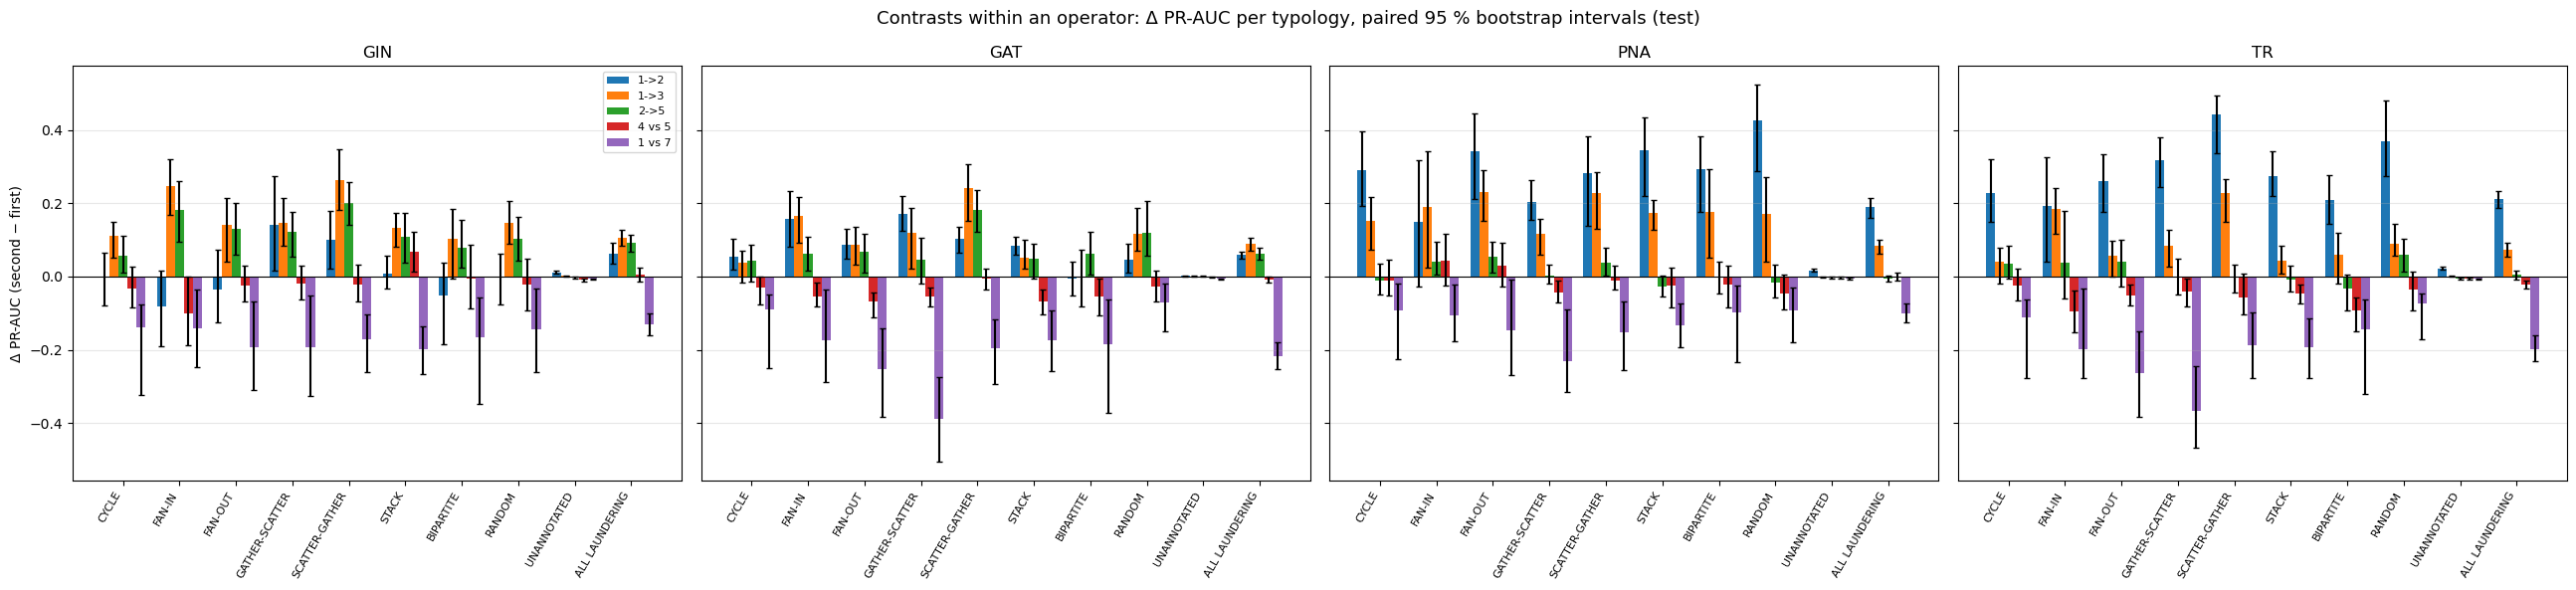

In [24]:
CONTRAST_COLOR = dict(zip([c[0] for c in CONTRASTS], ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']))

fig, axes = plt.subplots(1, 4, figsize=(26, 6), sharey=True)
x, width = np.arange(len(ROWS)), 0.16
for ax, family in zip(axes, FAMILY_ORDER):
    sub = contrasts[(contrasts['family'] == family) & (contrasts['metric'] == 'pr_auc')]
    for j, (name, _, _) in enumerate(CONTRASTS):
        table = sub[sub['contrast'] == name].set_index('typology').reindex(ROWS)
        ax.bar(x + (j - 2) * width, table['delta'], width, color=CONTRAST_COLOR[name], label=name,
               yerr=np.clip([table['delta'] - table['lo'], table['hi'] - table['delta']], 0, None), capsize=2)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(ROWS, rotation=60, ha='right', fontsize=8)
    ax.set_title(family)
    ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('Δ PR-AUC (second − first)')
axes[0].legend(fontsize=8)
fig.suptitle('Contrasts within an operator: Δ PR-AUC per typology, paired 95 % bootstrap intervals (test)', fontsize=13)
fig.tight_layout()
fig.savefig(f'{OUT}/contrast_pr_auc_test.png', dpi=120)
plt.show()

## 12. Do RWPE and the tuned GFP sheet help specific typologies?

**Hypotheses, stated before the results** (the sections above were computed first, this cell was written before the uplift cells were run):
- **tuned** (cycles ≤ 12 hops, 48 h windows, 4 bins) helps **CYCLE**; possibly **RANDOM**, **FAN-IN**, **FAN-OUT** (longer windows see more of a fan or chain). Every other typology is exploratory.
- **RWPE** (directed random-walk return probabilities, k = 16) helps **CYCLE**. Every other typology is exploratory.

**Protocol, fixed now:**
- Pairs: V0 vs RWPE and V0 vs tuned for config 5 and config 4 of every operator (16 pairs) × typology, on the same paired draws.
- Deciding metric: Δ PR-AUC. Δ recall@1 %, Δ recall@5 % and Δ attempt recall are support; recall at the saved threshold is shown but never used (the variants moved the validation threshold).
- Verdict per variant × config × typology: **UPLIFT** if Δ PR-AUC > 0 in ≥ 3 of the 4 operators **and** its paired 95 % interval excludes 0 in ≥ 2 of them; **DROP** = the same with < 0; otherwise **TIE** (one operator alone with an interval excluding 0 = "hint, single run").
- Caveat: the intervals reflect test-sample variation only, not training seeds. Any uplift must survive the seed cross-check before it becomes a thesis finding.
- Outputs: `variant_uplift_test.csv`, `uplift_rwpe_test.png`, `uplift_tuned_test.png`.

In [25]:
VARIANTS = {'rwpe16': ' + RWPE', 'tuned': ' + tuned'}
UPLIFT_METRICS = ('pr_auc', 'recall_at_1pct', 'recall_at_5pct', 'attempt_recall', 'recall')

uplift_rows = []
for variant, suffix in VARIANTS.items():
    for config in (5, 4):
        for family in FAMILY_ORDER:
            for typology in ROWS:
                for metric in UPLIFT_METRICS:
                    base, with_variant = f'{family}-{config}', f'{family}-{config}{suffix}'
                    delta, lo, hi, verdict = paired_delta(base, with_variant, typology, metric)
                    uplift_rows.append({'variant': variant, 'config': config, 'family': family, 'typology': typology,
                                        'metric': metric, 'role': 'deciding' if metric == 'pr_auc' else ('shown' if metric == 'recall' else 'support'),
                                        'v0_value': point[(base, typology)][metric], 'variant_value': point[(with_variant, typology)][metric],
                                        'delta': delta, 'lo': lo, 'hi': hi, 'ci_excludes_0': verdict != 'tie', 'direction': verdict})
uplift = pd.DataFrame(uplift_rows)


def verdict(group):
    '''UPLIFT / DROP / TIE rule over the four operators of one variant x config x typology (Δ PR-AUC),
    plus the operator counts behind it: Δ > 0 / interval above 0 / interval below 0.'''
    n_pos, n_neg = int((group['delta'] > 0).sum()), int((group['delta'] < 0).sum())
    n_ci_pos, n_ci_neg = int((group['lo'] > 0).sum()), int((group['hi'] < 0).sum())
    if n_pos >= 3 and n_ci_pos >= 2:
        label = 'UPLIFT'
    elif n_neg >= 3 and n_ci_neg >= 2:
        label = 'DROP'
    else:
        label = 'TIE (hint, single run)' if n_ci_pos + n_ci_neg == 1 else 'TIE'
    return pd.Series({'verdict': label, 'operators_up': n_pos, 'operators_sig_up': n_ci_pos, 'operators_sig_down': n_ci_neg})


verdicts = (uplift[uplift['metric'] == 'pr_auc'].groupby(['variant', 'config', 'typology'], observed=True)
            .apply(verdict, include_groups=False).reset_index())
uplift = uplift.merge(verdicts, on=['variant', 'config', 'typology'], how='left')
assert uplift['verdict'].notna().all() and len(verdicts) == 2 * 2 * len(ROWS)
uplift.to_csv(f'{OUT}/variant_uplift_test.csv', index=False)
print(f'{len(uplift)} rows -> {OUT}/variant_uplift_test.csv')

print('Verdict on Δ PR-AUC (rule above), per variant x config x typology; in brackets: operators with Δ > 0 / interval above 0 / interval below 0')
verdict_text = verdicts.apply(lambda r: f'{r["verdict"]} [{r["operators_up"]}/{r["operators_sig_up"]}/{r["operators_sig_down"]}]', axis=1)
display(verdicts.assign(cell=verdict_text).pivot(index='typology', columns=['variant', 'config'], values='cell').reindex(ROWS))
for variant in VARIANTS:
    cell = uplift.apply(lambda r: f'{r["delta"]:+.3f} [{r["lo"]:+.3f}, {r["hi"]:+.3f}]' + (' *' if r['ci_excludes_0'] else ''), axis=1)
    sub = uplift[(uplift['variant'] == variant) & (uplift['metric'] == 'pr_auc')]
    print(f'\nΔ PR-AUC, V0 -> {variant} (paired 95 % interval; * = interval excludes 0)')
    display(sub.assign(cell=cell[sub.index]).pivot(index='typology', columns=['config', 'family'], values='cell').reindex(ROWS))

800 rows -> Outputs/TYPOLOGY/variant_uplift_test.csv
Verdict on Δ PR-AUC (rule above), per variant x config x typology; in brackets: operators with Δ > 0 / interval above 0 / interval below 0


variant                                 rwpe16                                                           tuned                                
config                                       4                               5                               4                               5
typology                                                                                                                                      
CYCLE                              TIE [1/0/0]  TIE (hint, single run) [3/1/0]  TIE (hint, single run) [1/0/1]                     TIE [2/0/2]
FAN-IN          TIE (hint, single run) [2/0/1]                  UPLIFT [3/2/1]                     TIE [0/0/0]                    DROP [1/0/2]
FAN-OUT                            TIE [3/0/0]  TIE (hint, single run) [1/1/0]                     TIE [2/0/0]                     TIE [2/1/2]
GATHER-SCATTER  TIE (hint, single run) [2/0/1]                  UPLIFT [3/3/1]                    DROP [1/0/2]                     TIE [2/1/2]
SCATTER-GATHER                     TIE [2/0/0]                     TIE [3/0/0]                    DROP [1/0/2]  TIE (hint, single run) [2/0/1]
STACK           TIE (hint, single run) [1/0/1]                  UPLIFT [3/2/0]                    DROP [1/0/3]                     TIE [2/1/1]
BIPARTITE       TIE (hint, single run) [3/0/1]                  UPLIFT [4/2/0]                    DROP [0/0/2]                     TIE [2/1/2]
RANDOM          TIE (hint, single run) [0/0/1]  TIE (hint, single run) [4/1/0]                    DROP [0/0/3]                    DROP [1/0/2]
UNANNOTATED     TIE (hint, single run) [0/0/1]                     TIE [3/1/1]                     TIE [2/0/0]                  UPLIFT [3/2/0]
ALL LAUNDERING                     TIE [2/0/0]                     TIE [3/1/1]                    DROP [1/1/3]                     TIE [2/2/2]


Δ PR-AUC, V0 -> rwpe16 (paired 95 % interval; * = interval excludes 0)


config                                  5                                                                                                           4                             \
family                                GIN                        GAT                        PNA                         TR                        GIN                        GAT   
typology                                                                                                                                                                           
CYCLE             +0.013 [-0.053, +0.073]  +0.024 [+0.003, +0.048] *    +0.010 [-0.021, +0.048]    -0.019 [-0.058, +0.033]    +0.028 [-0.018, +0.098]    -0.003 [-0.036, +0.031]   
FAN-IN          -0.114 [-0.222, -0.016] *  +0.024 [+0.002, +0.043] *  +0.042 [+0.010, +0.071] *    +0.025 [-0.020, +0.061]    +0.037 [-0.035, +0.105]  -0.025 [-0.056, -0.003] *   
FAN-OUT           -0.066 [-0.143, +0.007]  +0.097 [+0.050, +0.145] *    -0.017 [-0.058, +0.038]    -0.014 [-0.043, +0.010]    +0.042 [-0.016, +0.105]    +0.010 [-0.022, +0.042]   
GATHER-SCATTER  -0.063 [-0.130, -0.003] *  +0.036 [+0.017, +0.059] *  +0.034 [+0.004, +0.055] *  +0.028 [+0.002, +0.066] *    +0.035 [-0.010, +0.084]    -0.021 [-0.056, +0.013]   
SCATTER-GATHER    -0.055 [-0.117, +0.017]    +0.035 [-0.003, +0.070]    +0.035 [-0.007, +0.072]    +0.020 [-0.005, +0.048]    -0.028 [-0.122, +0.087]    +0.016 [-0.016, +0.056]   
STACK             -0.021 [-0.073, +0.037]  +0.054 [+0.032, +0.083] *  +0.029 [+0.007, +0.059] *    +0.013 [-0.018, +0.052]    +0.032 [-0.008, +0.075]    -0.020 [-0.055, +0.020]   
BIPARTITE         +0.034 [-0.025, +0.099]  +0.078 [+0.040, +0.130] *    +0.050 [-0.010, +0.138]  +0.053 [+0.001, +0.112] *    +0.078 [-0.007, +0.203]    +0.010 [-0.044, +0.080]   
RANDOM            +0.002 [-0.060, +0.055]    +0.025 [-0.025, +0.074]  +0.067 [+0.017, +0.112] *    +0.001 [-0.046, +0.081]    -0.018 [-0.082, +0.068]    -0.014 [-0.044, +0.029]   
UNANNOTATED       +0.002 [-0.000, +0.005]  -0.001 [-0.002, -0.000] *    +0.002 [-0.000, +0.004]  +0.003 [+0.001, +0.005] *  -0.006 [-0.009, -0.003] *    -0.001 [-0.002, +0.000]   
ALL LAUNDERING  -0.049 [-0.068, -0.030] *  +0.019 [+0.011, +0.026] *    +0.004 [-0.002, +0.011]    +0.007 [-0.001, +0.015]    -0.014 [-0.030, +0.003]    +0.002 [-0.007, +0.012]   

config                                                              
family                                PNA                       TR  
typology                                                            
CYCLE             -0.051 [-0.095, +0.010]  -0.028 [-0.061, +0.003]  
FAN-IN            -0.008 [-0.076, +0.073]  +0.025 [-0.012, +0.055]  
FAN-OUT           -0.037 [-0.081, +0.010]  +0.009 [-0.051, +0.073]  
GATHER-SCATTER  -0.063 [-0.094, -0.032] *  +0.005 [-0.037, +0.039]  
SCATTER-GATHER    -0.027 [-0.081, +0.021]  +0.027 [-0.014, +0.085]  
STACK           -0.051 [-0.080, -0.020] *  -0.005 [-0.044, +0.027]  
BIPARTITE       -0.095 [-0.122, -0.063] *  +0.047 [-0.002, +0.076]  
RANDOM          -0.094 [-0.183, -0.032] *  -0.009 [-0.079, +0.056]  
UNANNOTATED       -0.000 [-0.003, +0.003]  -0.002 [-0.004, +0.000]  
ALL LAUNDERING    -0.006 [-0.017, +0.002]  +0.000 [-0.010, +0.012]


Δ PR-AUC, V0 -> tuned (paired 95 % interval; * = interval excludes 0)


config                                  5                                                                                                           4                             \
family                                GIN                        GAT                        PNA                         TR                        GIN                        GAT   
typology                                                                                                                                                                           
CYCLE           -0.064 [-0.105, -0.025] *    +0.016 [-0.006, +0.054]  -0.051 [-0.092, -0.018] *    +0.020 [-0.017, +0.061]    -0.034 [-0.080, +0.018]    +0.008 [-0.024, +0.052]   
FAN-IN          -0.077 [-0.128, -0.022] *    -0.003 [-0.022, +0.032]  -0.059 [-0.101, -0.021] *    +0.059 [-0.014, +0.097]    -0.019 [-0.085, +0.061]    -0.012 [-0.052, +0.026]   
FAN-OUT         -0.103 [-0.181, -0.029] *  +0.064 [+0.011, +0.145] *  -0.078 [-0.108, -0.038] *    +0.023 [-0.015, +0.060]    +0.008 [-0.062, +0.085]    +0.028 [-0.024, +0.093]   
GATHER-SCATTER  -0.053 [-0.098, -0.012] *    +0.029 [-0.004, +0.055]  -0.022 [-0.044, -0.004] *  +0.046 [+0.018, +0.082] *    -0.045 [-0.107, +0.019]    +0.009 [-0.011, +0.033]   
SCATTER-GATHER  -0.121 [-0.156, -0.084] *    +0.007 [-0.041, +0.045]    -0.030 [-0.067, +0.005]    +0.022 [-0.022, +0.052]  -0.090 [-0.157, -0.014] *    +0.022 [-0.033, +0.071]   
STACK           -0.108 [-0.143, -0.077] *  +0.044 [+0.011, +0.085] *    -0.036 [-0.067, +0.005]    +0.019 [-0.004, +0.049]  -0.069 [-0.114, -0.024] *    +0.023 [-0.030, +0.073]   
BIPARTITE       -0.095 [-0.167, -0.047] *    +0.014 [-0.047, +0.055]  -0.080 [-0.114, -0.035] *  +0.037 [+0.001, +0.068] *    -0.059 [-0.125, +0.010]    -0.031 [-0.103, +0.042]   
RANDOM          -0.095 [-0.143, -0.046] *    +0.023 [-0.002, +0.067]  -0.089 [-0.130, -0.043] *    -0.015 [-0.067, +0.034]  -0.067 [-0.127, -0.009] *    -0.027 [-0.077, +0.023]   
UNANNOTATED       +0.001 [-0.001, +0.003]  +0.002 [+0.001, +0.004] *    -0.002 [-0.004, +0.001]  +0.004 [+0.001, +0.007] *    -0.000 [-0.004, +0.003]    +0.001 [-0.001, +0.002]   
ALL LAUNDERING  -0.031 [-0.044, -0.018] *  +0.025 [+0.014, +0.036] *  -0.009 [-0.017, -0.000] *  +0.021 [+0.012, +0.029] *  -0.026 [-0.040, -0.011] *  +0.019 [+0.007, +0.030] *   

config                                                                
family                                PNA                         TR  
typology                                                              
CYCLE           -0.143 [-0.196, -0.090] *    -0.047 [-0.080, +0.002]  
FAN-IN            -0.020 [-0.081, +0.036]    -0.022 [-0.069, +0.049]  
FAN-OUT           -0.049 [-0.119, +0.023]    -0.020 [-0.070, +0.046]  
GATHER-SCATTER  -0.057 [-0.085, -0.026] *  -0.055 [-0.088, -0.029] *  
SCATTER-GATHER  -0.048 [-0.096, -0.016] *    -0.029 [-0.063, +0.010]  
STACK           -0.068 [-0.115, -0.025] *  -0.061 [-0.087, -0.031] *  
BIPARTITE       -0.181 [-0.224, -0.127] *  -0.130 [-0.154, -0.083] *  
RANDOM          -0.190 [-0.225, -0.158] *  -0.101 [-0.148, -0.036] *  
UNANNOTATED       +0.003 [-0.001, +0.006]    -0.001 [-0.003, +0.002]  
ALL LAUNDERING  -0.014 [-0.025, -0.002] *  -0.011 [-0.020, -0.000] *

In [26]:
print('support metrics, counted over the four operators: operators with Δ > 0 / with interval excluding 0 above / below')
support = uplift[uplift['metric'].isin(['recall_at_1pct', 'recall_at_5pct', 'attempt_recall'])]
summary = support.groupby(['variant', 'config', 'typology', 'metric'], observed=True).apply(
    lambda g: f'{int((g["delta"] > 0).sum())} up / {int((g["lo"] > 0).sum())} sig up / {int((g["hi"] < 0).sum())} sig down',
    include_groups=False).rename('operators').reset_index()
display(summary.pivot(index=['typology', 'metric'], columns=['variant', 'config'], values='operators')
        .reindex(pd.MultiIndex.from_product([ROWS, ['recall_at_1pct', 'recall_at_5pct', 'attempt_recall']])))

support metrics, counted over the four operators: operators with Δ > 0 / with interval excluding 0 above / below


variant                                              rwpe16                                                       tuned                              
config                                                    4                             5                             4                             5
CYCLE          recall_at_1pct  2 up / 0 sig up / 0 sig down  2 up / 0 sig up / 1 sig down  2 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down
               recall_at_5pct  3 up / 0 sig up / 0 sig down  0 up / 0 sig up / 1 sig down  2 up / 0 sig up / 0 sig down  0 up / 0 sig up / 1 sig down
               attempt_recall  1 up / 0 sig up / 0 sig down  3 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  3 up / 0 sig up / 0 sig down
FAN-IN         recall_at_1pct  0 up / 0 sig up / 0 sig down  2 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  2 up / 0 sig up / 0 sig down
               recall_at_5pct  2 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  0 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down
               attempt_recall  2 up / 0 sig up / 0 sig down  0 up / 0 sig up / 1 sig down  2 up / 0 sig up / 0 sig down  3 up / 0 sig up / 0 sig down
FAN-OUT        recall_at_1pct  3 up / 0 sig up / 0 sig down  1 up / 0 sig up / 1 sig down  3 up / 1 sig up / 0 sig down  2 up / 0 sig up / 0 sig down
               recall_at_5pct  2 up / 0 sig up / 0 sig down  0 up / 0 sig up / 0 sig down  4 up / 1 sig up / 0 sig down  0 up / 0 sig up / 0 sig down
               attempt_recall  3 up / 0 sig up / 0 sig down  1 up / 0 sig up / 1 sig down  3 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down
GATHER-SCATTER recall_at_1pct  2 up / 0 sig up / 0 sig down  2 up / 0 sig up / 1 sig down  1 up / 0 sig up / 1 sig down  3 up / 0 sig up / 1 sig down
               recall_at_5pct  0 up / 0 sig up / 0 sig down  0 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down
               attempt_recall  0 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  2 up / 0 sig up / 0 sig down
SCATTER-GATHER recall_at_1pct  2 up / 1 sig up / 0 sig down  2 up / 0 sig up / 1 sig down  1 up / 0 sig up / 1 sig down  2 up / 0 sig up / 0 sig down
               recall_at_5pct  1 up / 0 sig up / 0 sig down  3 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  3 up / 0 sig up / 0 sig down
               attempt_recall  4 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  3 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down
STACK          recall_at_1pct  1 up / 0 sig up / 1 sig down  1 up / 0 sig up / 1 sig down  1 up / 0 sig up / 2 sig down  2 up / 0 sig up / 1 sig down
               recall_at_5pct  2 up / 1 sig up / 0 sig down  0 up / 0 sig up / 1 sig down  2 up / 0 sig up / 1 sig down  2 up / 0 sig up / 1 sig down
               attempt_recall  1 up / 0 sig up / 0 sig down  0 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down
BIPARTITE      recall_at_1pct  2 up / 0 sig up / 0 sig down  2 up / 0 sig up / 1 sig down  2 up / 0 sig up / 0 sig down  1 up / 0 sig up / 1 sig down
               recall_at_5pct  1 up / 0 sig up / 0 sig down  2 up / 0 sig up / 1 sig down  3 up / 0 sig up / 0 sig down  2 up / 0 sig up / 1 sig down
               attempt_recall  2 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  2 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down
RANDOM         recall_at_1pct  1 up / 0 sig up / 0 sig down  0 up / 0 sig up / 0 sig down  0 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down
               recall_at_5pct  1 up / 0 sig up / 0 sig down  0 up / 0 sig up / 0 sig down  0 up / 0 sig up / 0 sig down  0 up / 0 sig up / 0 sig down
               attempt_recall  2 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down  2 up / 0 sig up / 0 sig down  1 up / 0 sig up / 0 sig down
UNANNOTATED    recall_at_1pct  1 up / 0 sig up / 0 sig down  2 up / 0 sig up / 0 sig down  1 up / 1 

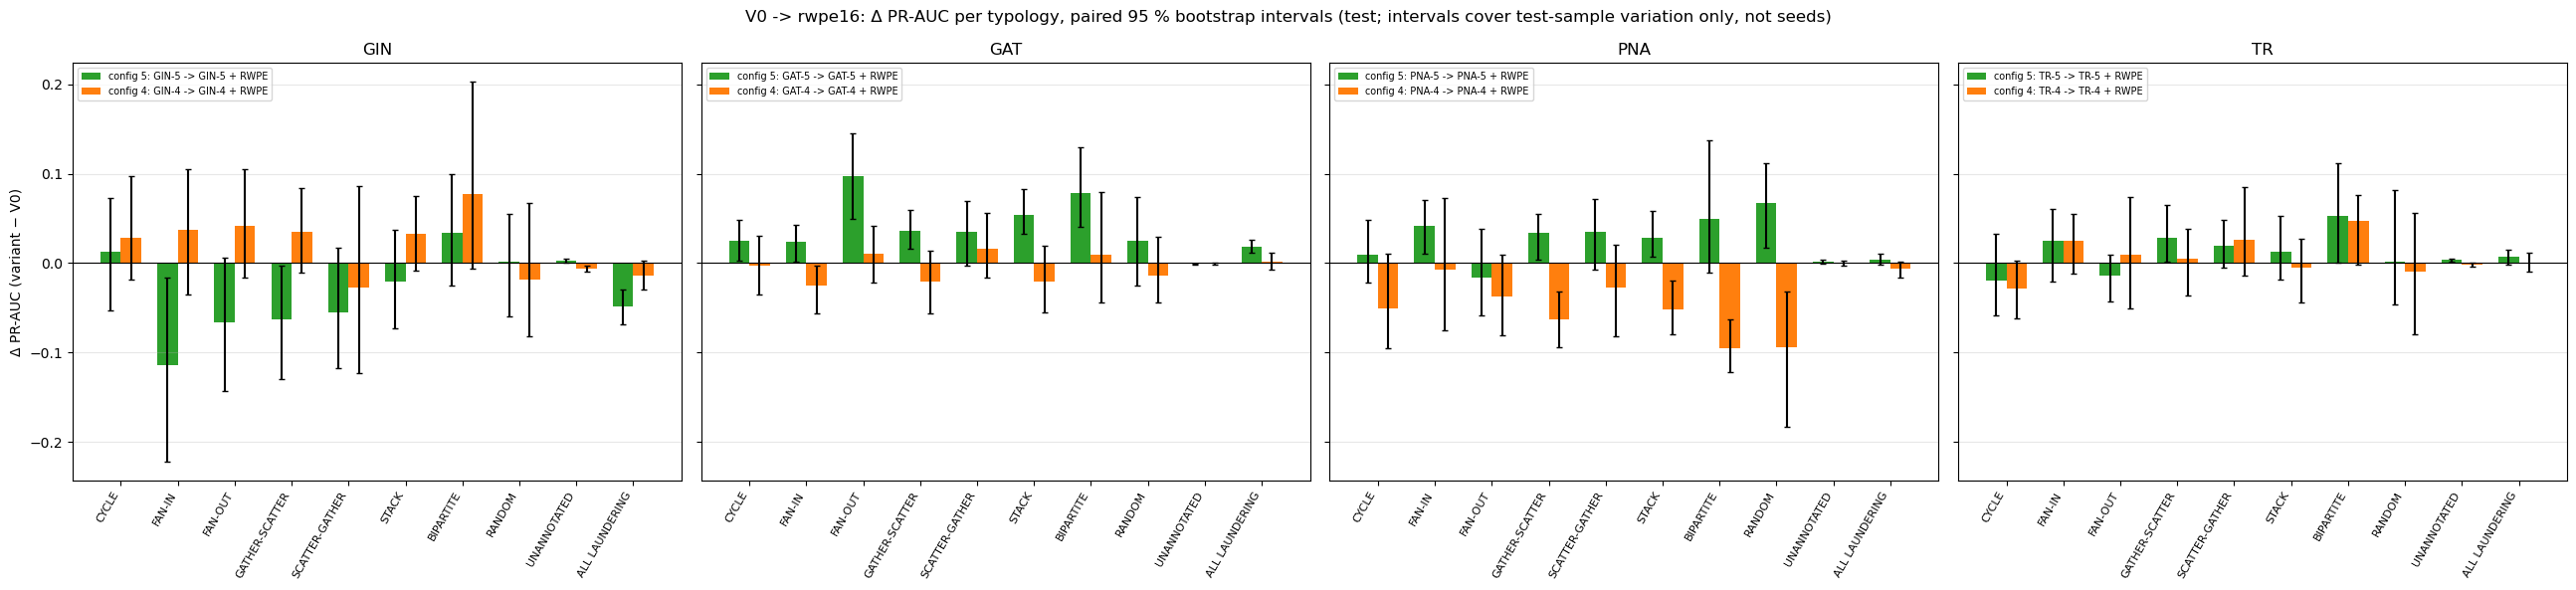

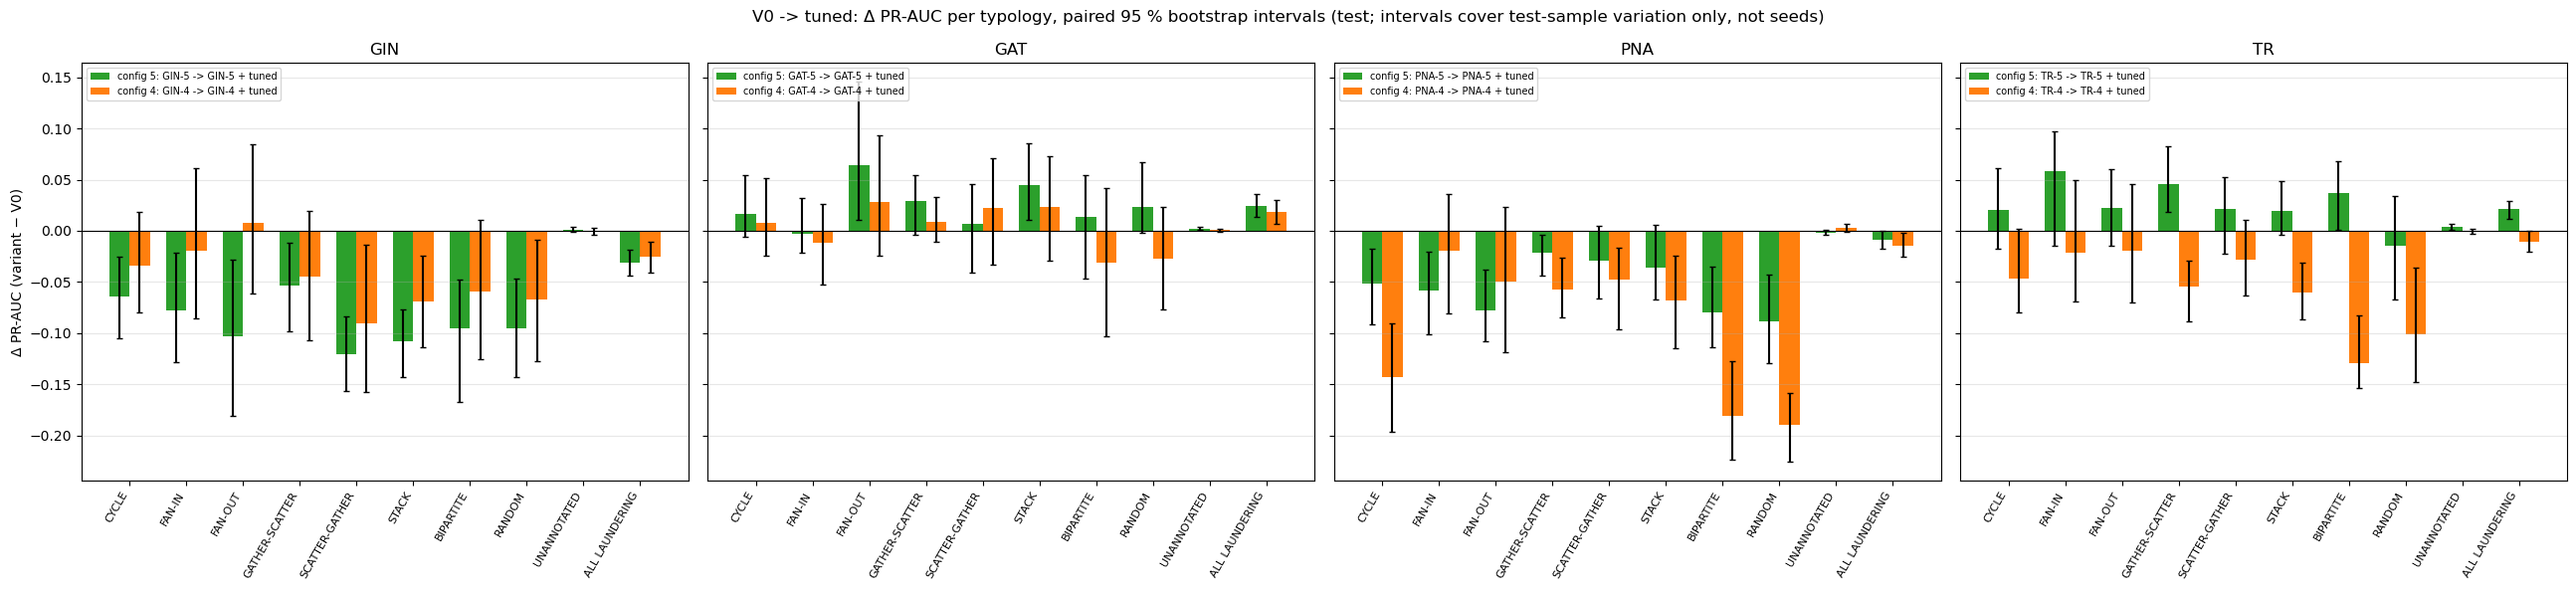

In [27]:
for variant, suffix in VARIANTS.items():
    fig, axes = plt.subplots(1, 4, figsize=(26, 6), sharey=True)
    x, width = np.arange(len(ROWS)), 0.36
    for ax, family in zip(axes, FAMILY_ORDER):
        sub = uplift[(uplift['variant'] == variant) & (uplift['family'] == family) & (uplift['metric'] == 'pr_auc')]
        for j, config in enumerate((5, 4)):
            table = sub[sub['config'] == config].set_index('typology').reindex(ROWS)
            ax.bar(x + (j - 0.5) * width, table['delta'], width, color=CONFIG_COLOR[config], label=f'config {config}: {family}-{config} -> {family}-{config}{suffix}',
                   yerr=np.clip([table['delta'] - table['lo'], table['hi'] - table['delta']], 0, None), capsize=2)
        ax.axhline(0, color='black', lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(ROWS, rotation=60, ha='right', fontsize=8)
        ax.set_title(family)
        ax.legend(fontsize=7, loc='upper left')
        ax.grid(axis='y', alpha=0.3)
    axes[0].set_ylabel('Δ PR-AUC (variant − V0)')
    fig.suptitle(f'V0 -> {variant}: Δ PR-AUC per typology, paired 95 % bootstrap intervals (test; intervals cover test-sample variation only, not seeds)', fontsize=12)
    fig.tight_layout()
    fig.savefig(f'{OUT}/uplift_{"rwpe" if variant == "rwpe16" else "tuned"}_test.png', dpi=120)
    plt.show()

## 13. Output files

- Everything this notebook writes, checked to exist. The per-draw `.npz` is the only large file (float32, 44 × 10 × 7 × 1,000 values; not versioned).

In [28]:
expected_png = ['recall_heatmap_test.png', 'bars_recall_test.png', 'bars_precision_test.png', 'bars_f1_test.png',
                'bars_pr_auc_test.png', 'bars_variants_recall_config5_test.png', 'bars_variants_pr_auc_config5_test.png',
                'bars_variants_recall_config4_test.png', 'bars_variants_pr_auc_config4_test.png',
                'contrast_pr_auc_test.png', 'uplift_rwpe_test.png', 'uplift_tuned_test.png']
expected_csv = ['edge_typology.csv', 'typology_counts.csv', 'typology_metrics_test.csv', 'typology_metrics_test_intervals.csv',
                'fresh_vs_continued_test.csv', 'typology_contrasts_test.csv', 'variant_uplift_test.csv']
for name in expected_png + expected_csv + ['bootstrap_draws_test.npz']:
    assert os.path.exists(f'{OUT}/{name}'), name
    print(f'{name:40s} {os.path.getsize(f"{OUT}/{name}") / 1024:8.0f} KB')
print(f'\n{len(expected_png)} figures, {len(expected_csv)} tables, 1 draws file in {OUT}/')

recall_heatmap_test.png                       345 KB
bars_recall_test.png                          102 KB
bars_precision_test.png                       101 KB
bars_f1_test.png                              100 KB
bars_pr_auc_test.png                          104 KB
bars_variants_recall_config5_test.png         103 KB
bars_variants_pr_auc_config5_test.png         106 KB
bars_variants_recall_config4_test.png         104 KB
bars_variants_pr_auc_config4_test.png         106 KB
contrast_pr_auc_test.png                       85 KB
uplift_rwpe_test.png                           93 KB
uplift_tuned_test.png                         100 KB
edge_typology.csv                             122 KB
typology_counts.csv                             1 KB
typology_metrics_test.csv                     117 KB
typology_metrics_test_intervals.csv           189 KB
fresh_vs_continued_test.csv                    30 KB
typology_contrasts_test.csv                   140 KB
variant_uplift_test.csv                       